# MILK10k — Pure 11-Class Macro-OVR Experiment (384×384)

**Purpose:** a separate 384×384 experiment that trains and selects models using only the original 11 diagnosis classes.

## Experiment configuration
- Image resolution: **384 × 384**
- Backbone: shared ConvNeXtV2 Tiny for dermoscopic + clinical images
- Fusion: concatenate both image embeddings with age/site metadata
- Training objective: **11-class weighted cross-entropy only**
- Class-weight power: **0.65** (softened inverse-frequency weighting)
- Binary-group weighting: **removed**
- Auxiliary binary head / binary targets / binary metrics: **removed**
- Effective batch size: **16** (physical batch 8 × accumulation 2)
- Early-stopping patience: **6 epochs**

## Checkpoint selection — only three metrics
For each validation epoch, compute the same one-vs-rest balanced-accuracy metrics from the 11-class argmax predictions:
1. **11-class Macro OVR BA** — primary selection metric.
2. **Fixed Top-6 OVR BA** — first tie-breaker.
3. **Fixed Top-4 OVR BA** — second tie-breaker.

Checkpoints are ranked lexicographically by `(Macro OVR, Top-6 OVR, Top-4 OVR)`. Early stopping tracks improvement under exactly this ranking. No binary BA constraint, threshold search, binary loss, or binary-based checkpoint criterion is used.

*Top-4 and Top-6 are overlapping subsets of the 11 classes. They are used as tie-breakers, not added to Macro OVR, so the full 11-class macro metric remains the primary objective.*

## Experiment boundaries
- Uses the same lesion-level five-fold development split and fold-specific metadata preprocessing.
- The previously used 524-lesion held-out test set is not evaluated.
- A dedicated `RUN_TAG` and output directory prevent overwriting earlier experiments.
- Run each fold (0–4) with the same configuration, then run the pooled OOF evaluation cell.

## What changed from the previous Macro-OVR notebook
1. Removed binary mapping/labels from sample preparation.
2. Removed the optional binary classifier and all binary evaluation / threshold code.
3. Removed binary-group balancing from the 11-class loss weights.
4. Checkpoint selection and early stopping now use only Macro OVR, Top-6 OVR and Top-4 OVR.
5. Pooled OOF output stores only 11-class probabilities and 11-class labels.

**Research use only. This notebook is not a clinically validated diagnostic system.**


In [1]:
import os, math, time, copy, random, warnings, json, glob, re
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
from dataclasses import dataclass

import numpy as np
import pandas as pd
import cv2
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.metrics import balanced_accuracy_score, confusion_matrix
from sklearn.model_selection import StratifiedKFold, train_test_split
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

@dataclass
class CFG:
    seed: int = 42
    device: str = 'cuda' if torch.cuda.is_available() else 'cpu'
    fold_to_run: int = 0                # change to 1, 2, 3, 4 for the remaining folds
    img_size: int = 256
    epochs: int = 20
    patience: int = 6
    warmup_epochs: int = 2
    freeze_epochs: int = 1
    batch_size: int = 8
    grad_accum_steps: int = 2           # effective batch 16
    eval_batch_size: int = 8
    num_workers: int = 2
    cache_workers: int = 4
    head_lr: float = 2e-4
    base_lr: float = 3e-5
    min_lr_ratio: float = 0.02
    weight_decay: float = 0.02
    grad_clip: float = 1.0
    dropout: float = 0.20
    drop_path: float = 0.10
    label_smoothing: float = 0.05
    class_weight_power: float = 0.5
    ema_decay: float = 0.996
    n_splits: int = 5
    test_size: float = 0.10
    backbone: str = 'convnextv2_tiny'
    use_grad_checkpointing: bool = True
    site_embedding_dim: int = 16
    metadata_hidden_dim: int = 128
    cache_max_side: int = 900

    # Input data locations configured locally / in Colab.
    base: str = '/content/MILK10k_image_metadata_fusion'
    src_images_dir: str = '/content/MILK10k_Training_Input'
    metadata_csv: str = '/content/MILK10k_Training_Metadata.csv'
    groundtruth_csv: str = '/content/MILK10k_Training_GroundTruth.csv'

cfg = CFG()


# Dedicated output namespace; this run cannot overwrite earlier v2/v3/Macro-OVR outputs.
RUN_TAG = (
    f'pure11_macroovr_img{cfg.img_size}_cw{cfg.class_weight_power:.2f}_'
    f'b{cfg.batch_size}x{cfg.grad_accum_steps}_seed{cfg.seed}'
)

DEVICE = cfg.device
CACHE_VERSION = 'dualview_320_metadata_age_site_v1'
CACHE_ROOT = os.path.join(cfg.base, 'cache', CACHE_VERSION)
DERM_CACHE_DIR = os.path.join(CACHE_ROOT, 'dermoscopic')
CLIN_CACHE_DIR = os.path.join(CACHE_ROOT, 'clinical')
MODEL_DIR = os.path.join(cfg.base, f'models_image_metadata_fusion_{RUN_TAG}')

for directory in [cfg.base, CACHE_ROOT, DERM_CACHE_DIR, CLIN_CACHE_DIR, MODEL_DIR,
                  os.path.join(cfg.base, 'logs')]:
    os.makedirs(directory, exist_ok=True)

print('PyTorch:', torch.__version__, '| CUDA available:', torch.cuda.is_available())
print(f'Run: {RUN_TAG}')
print(f'Device: {DEVICE} | fold: {cfg.fold_to_run}/{cfg.n_splits - 1}')
print(f'Image size: {cfg.img_size} x {cfg.img_size} | batch: {cfg.batch_size} | '
      f'accumulation: {cfg.grad_accum_steps} | effective batch: {cfg.batch_size * cfg.grad_accum_steps}')
print(f'11-class weighted CE only | class-weight power: {cfg.class_weight_power:.2f}')
print('Checkpoint ranking: Macro OVR → Top-6 OVR → Top-4 OVR')
print(f'Early-stopping patience: {cfg.patience} epochs')
if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    print(f'GPU: {props.name} | VRAM: {props.total_memory / (1024**3):.1f} GiB')
    torch.backends.cudnn.benchmark = True
    torch.backends.cuda.matmul.allow_tf32 = True


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

seed_everything(cfg.seed + cfg.fold_to_run)


PyTorch: 2.14.1+cu130 | CUDA available: True
Run: pure11_macroovr_img256_cw0.50_b8x2_seed42
Device: cuda | fold: 0/4
Image size: 256 x 256 | batch: 8 | accumulation: 2 | effective batch: 16
11-class weighted CE only | class-weight power: 0.50
Checkpoint ranking: Macro OVR → Top-6 OVR → Top-4 OVR
Early-stopping patience: 6 epochs
GPU: Tesla T4 | VRAM: 14.6 GiB


In [2]:
# %% 3 — Download data (skip if files already in /content — Colab wipes /content on disconnect, Drive does NOT)
need = not (os.path.exists(cfg.groundtruth_csv) and os.path.exists(cfg.metadata_csv) and os.path.isdir(cfg.src_images_dir))
if need:
    print('Downloading (first session only)...')
    get_ipython().system('gdown --id 1keRWrLIpi6lFiV-KsSoMrI-T-Qy9fd_y')
    get_ipython().system('gdown --id 1K6nCC4k2yW9uv1gky7fmKCbrHd5kazK6')
    get_ipython().system('gdown --id 1EmRfhgtfaqJqhrHNF7A9V0JigZpsv7rd')

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From: https://drive.google.com/uc?id=1keRWrLIpi6lFiV-KsSoMrI-T-Qy9fd_y
To: /content/MILK10k_Training_GroundTruth.csv
100% 294k/294k [00:00<00:00, 105MB/s]
/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1K6nCC4k2yW9uv1gky7fmKCbrHd5kazK6
From (redirected): https://drive.google.com/uc?id=1K6nCC4k2yW9uv1gky7fmKCbrHd5kazK6&confirm=t&uuid=7222a1ee-2194-4e48-91c3-245457295960
To: /content/MILK10k_Training_Input.zip
100% 329M/329M [00:02<00:00, 139MB/s]
/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning:

In [3]:
!unzip -q /content/MILK10k_Training_Input.zip

In [4]:
# %% 4 — Original 11 diagnosis labels + lesion-level held-out TEST split
import re
df = pd.read_csv(cfg.groundtruth_csv)
meta_raw = pd.read_csv(cfg.metadata_csv)

# Helper to resolve metadata column names
def resolve_column(frame, candidates, feature_name):
    lookup = {str(col).strip().lower(): col for col in frame.columns}
    for candidate in candidates:
        if candidate in lookup:
            return lookup[candidate]
    raise KeyError(f'Could not identify {feature_name} metadata column.')

AGE_META_COL = resolve_column(meta_raw, ['age_approx', 'age', 'age_approx_years', 'age_approx_5year'], 'age_approx')
SITE_META_COL = resolve_column(meta_raw, ['site', 'anatomic_site', 'anatomical_site', 'anatom_site_general', 'site_name'], 'site')

def parse_age_approx(value):
    if pd.isna(value):
        return np.nan
    try:
        return float(value)
    except (TypeError, ValueError):
        numbers = re.findall(r'\d+(?:\.\d+)?', str(value))
        if len(numbers) >= 2 and ('-' in str(value) or 'to' in str(value).lower()):
            return (float(numbers[0]) + float(numbers[1])) / 2.0
        if numbers:
            return float(numbers[0])
        return np.nan

def clean_site_value(value):
    if pd.isna(value) or str(value).strip() == '':
        return 'Unknown'
    return re.sub(r'\s+', ' ', str(value).strip().lower().replace('_', ' ')).title()

# Group raw metadata to lesion level (by taking first available non-null or using fallback)
meta_raw['parsed_age'] = meta_raw[AGE_META_COL].apply(parse_age_approx)
meta_raw['cleaned_site'] = meta_raw[SITE_META_COL].apply(clean_site_value)

# Do not impute age here. The median is fitted inside each fold's MetadataPreprocessor
# using only that fold's training lesions, then reused for validation and test.

# Collapse metadata to lesion-level to merge into ground truth
lesion_meta = meta_raw.groupby('lesion_id').agg({
    'parsed_age': 'first',
    'cleaned_site': 'first'
}).reset_index()

# Merge imputed features directly into main dataframe
df['lesion_id'] = df['lesion_id'].astype(str)
lesion_meta['lesion_id'] = lesion_meta['lesion_id'].astype(str)
df = df.merge(lesion_meta, on='lesion_id', how='left')

# Site is categorical and can safely map missing values to the explicit Unknown category.
# Age NaNs are intentionally retained until the per-fold training-only imputer is fitted.
df['cleaned_site'] = df['cleaned_site'].fillna('Unknown')

CLASSES = ['AKIEC','BCC','BEN_OTH','BKL','DF','INF','MAL_OTH','MEL','NV','SCCKA','VASC']
NUM_CLASSES = len(CLASSES)
CLASS_TO_IDX = {name: idx for idx, name in enumerate(CLASSES)}

# Fixed diagnostic groups chosen from the previously reported primary-configuration baseline.
FIXED_TOP4_CLASSES = ['NV', 'DF', 'BCC', 'SCCKA']
FIXED_TOP6_CLASSES = TOP6_CLASSES = FIXED_TOP4_CLASSES + ['MEL', 'AKIEC']


df['class_label'] = df[CLASSES].apply(lambda row: next((name for name in CLASSES if row[name] == 1), 'UNKNOWN'), axis=1)

outer_stratify_col = 'class_label'
trainval_lesions, test_lesions = train_test_split(
    df, test_size=cfg.test_size, random_state=cfg.seed, stratify=df[outer_stratify_col]
)
trainval_lesions = trainval_lesions.reset_index(drop=True)
test_lesions = test_lesions.reset_index(drop=True)

print(f'Train+Val: {len(trainval_lesions)} lesions | Test: {len(test_lesions)} lesions')

Train+Val: 4716 lesions | Test: 524 lesions


In [5]:
# %% 5 — Build lesion-matched image pairs with raw age and cleaned site (fold imputation later)
meta = pd.read_csv(cfg.metadata_csv)
meta['isic_id'] = meta['isic_id'].astype(str)
meta['image_type_norm'] = meta['image_type'].astype(str).str.strip().str.lower()
type_map = dict(zip(meta['isic_id'], meta['image_type_norm']))

IMAGE_EXTS = ('.jpg', '.jpeg', '.png')

def classify_image_type(image_type):
    value = str(image_type).lower().replace('_', ' ').replace('-', ' ')
    if 'dermoscop' in value:
        return 'dermoscopic'
    if 'clinical' in value or 'close up' in value or 'closeup' in value:
        return 'clinical'
    return 'other'

def build_sample_table(lesion_df, split_name):
    rows, missing_folder, missing_view = [], [], []
    for _, lesion in lesion_df.iterrows():
        lesion_id = str(lesion['lesion_id'])
        diagnosis = lesion['class_label']
        folder = os.path.join(cfg.src_images_dir, lesion_id)
        if not os.path.isdir(folder):
            missing_folder.append(lesion_id)
            continue

        derm_candidates, clinical_candidates = [], []
        for filename in sorted(os.listdir(folder)):
            if not filename.lower().endswith(IMAGE_EXTS):
                continue
            image_id = os.path.splitext(filename)[0]
            view = classify_image_type(type_map.get(image_id, 'unknown'))
            full_path = os.path.join(folder, filename)
            if view == 'dermoscopic':
                derm_candidates.append((image_id, full_path))
            elif view == 'clinical':
                clinical_candidates.append((image_id, full_path))

        if len(derm_candidates) != 1 or len(clinical_candidates) != 1:
            missing_view.append((lesion_id, len(derm_candidates), len(clinical_candidates)))
            continue

        derm_id, derm_path = derm_candidates[0]
        clinical_id, clinical_path = clinical_candidates[0]

        rows.append({
            'lesion_id': lesion_id,
            'isic_id': derm_id,
            'clinical_isic_id': clinical_id,
            'split': split_name,
            'derm_src_path': derm_path,
            'clinical_src_path': clinical_path,
            'derm_cache_path': os.path.join(DERM_CACHE_DIR, derm_id + '.jpg'),
            'clinical_cache_path': os.path.join(CLIN_CACHE_DIR, clinical_id + '.jpg'),
            'label': CLASS_TO_IDX[diagnosis],
            'class_label': diagnosis,
            'age_approx': lesion['parsed_age'],
            'site': lesion['cleaned_site'],
        })
    return pd.DataFrame(rows).reset_index(drop=True)

trainval_samples_all = build_sample_table(trainval_lesions, 'trainval')
print(f'Paired development lesions: {len(trainval_samples_all)}. The previously used test split is not loaded for v3 evaluation.')

Paired development lesions: 4716. The previously used test split is not loaded for v3 evaluation.


In [6]:
# %% 6 — Modality-specific preprocessing + max-side paired image cache (reused for 384 transforms)

def crop_dark_borders(img_np, threshold=12):
    """Remove only obvious dark outer borders, not the clinical/lesion field."""
    if img_np.ndim != 3 or img_np.shape[2] != 3:
        return img_np
    gray = cv2.cvtColor(img_np, cv2.COLOR_RGB2GRAY)
    mask = (gray > threshold).astype(np.uint8) * 255
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return img_np
    x, y, w, h = cv2.boundingRect(max(contours, key=cv2.contourArea))
    H, W = img_np.shape[:2]
    if w >= 0.50 * W and h >= 0.50 * H:
        return img_np[y:y+h, x:x+w]
    return img_np


def _clahe_luminance(img_np, clip_limit=2.0):
    lab = cv2.cvtColor(img_np, cv2.COLOR_RGB2LAB)
    l_channel, a_channel, b_channel = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=float(clip_limit), tileGridSize=(8, 8))
    l_channel = clahe.apply(l_channel)
    return cv2.cvtColor(cv2.merge((l_channel, a_channel, b_channel)), cv2.COLOR_LAB2RGB)


def preprocess_derm_np(img_np):
    """Dermoscopic-only: conservative border crop, hair inpainting, fixed luminance CLAHE."""
    img_np = np.ascontiguousarray(crop_dark_borders(img_np))
    gray = cv2.cvtColor(img_np, cv2.COLOR_RGB2GRAY)
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (17, 17))
    blackhat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, kernel)
    _, hair_mask = cv2.threshold(blackhat, 10, 255, cv2.THRESH_BINARY)
    inpainted = cv2.inpaint(img_np, hair_mask, 1, cv2.INPAINT_TELEA)
    return _clahe_luminance(inpainted, clip_limit=1.9)


def preprocess_clinical_np(img_np):
    """Clinical close-up: gentle border crop and mild luminance CLAHE; retain hair/context."""
    img_np = np.ascontiguousarray(crop_dark_borders(img_np))
    return _clahe_luminance(img_np, clip_limit=1.5)


def _resize_max_side(img, max_side):
    width, height = img.size
    scale = min(1.0, float(max_side) / max(width, height))
    if scale < 1.0:
        img = img.resize((max(1, round(width * scale)), max(1, round(height * scale))), Image.Resampling.LANCZOS)
    return img


def _cache_one(job):
    src_path, dst_path, modality = job
    if os.path.exists(dst_path):
        return None
    try:
        with Image.open(src_path) as image:
            img_np = np.asarray(image.convert('RGB'))
        if modality == 'dermoscopic':
            processed = preprocess_derm_np(img_np)
        elif modality == 'clinical':
            processed = preprocess_clinical_np(img_np)
        else:
            raise ValueError(f'Unknown modality: {modality}')
        output = _resize_max_side(Image.fromarray(processed), cfg.cache_max_side)
        os.makedirs(os.path.dirname(dst_path), exist_ok=True)
        output.save(dst_path, format='JPEG', quality=94, optimize=True)
        return None
    except Exception as exc:
        return (src_path, repr(exc))


def build_pair_cache(samples):
    jobs = []
    for row in samples.itertuples(index=False):
        jobs.append((row.derm_src_path, row.derm_cache_path, 'dermoscopic'))
        jobs.append((row.clinical_src_path, row.clinical_cache_path, 'clinical'))
    missing_jobs = [job for job in jobs if not os.path.exists(job[1])]
    if not missing_jobs:
        print(f'Paired cache already complete: {len(jobs)} images.')
        return
    print(f'Building {len(missing_jobs)} cache files ({len(jobs)} total paired views)...')
    cv2.setNumThreads(1)
    workers = max(1, min(cfg.cache_workers, os.cpu_count() or 1))
    with ThreadPoolExecutor(max_workers=workers) as pool:
        results = list(tqdm(pool.map(_cache_one, missing_jobs), total=len(missing_jobs), desc='preprocessing'))
    failures = [result for result in results if result is not None]
    print(f'Cache created: {len(missing_jobs) - len(failures)} | failed: {len(failures)}')
    if failures:
        print('First failures:', failures[:10])
        raise RuntimeError('Some images failed preprocessing; fix these before training.')

all_samples = trainval_samples_all.copy()
build_pair_cache(all_samples)
assert all(os.path.exists(path) for path in all_samples['derm_cache_path']), 'Some dermoscopic cache files are missing.'
assert all(os.path.exists(path) for path in all_samples['clinical_cache_path']), 'Some clinical cache files are missing.'
print('All development paired image cache files are available. The previously evaluated test images are not cached or inferred in this notebook.')

Building 9432 cache files (9432 total paired views)...


preprocessing:   0%|          | 0/9432 [00:00<?, ?it/s]

Cache created: 9432 | failed: 0
All development paired image cache files are available. The previously evaluated test images are not cached or inferred in this notebook.


In [7]:
# %% 7 — 384 x 384 paired Dataset (configurable via cfg.img_size) + fold-fitted age/site preprocessing
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]
S = cfg.img_size

derm_train_tf = transforms.Compose([
    transforms.RandomResizedCrop(S, scale=(0.82, 1.0), ratio=(0.90, 1.10)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.25),
    transforms.RandomRotation(25),
    transforms.ColorJitter(brightness=0.10, contrast=0.10, saturation=0.08, hue=0.01),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
    transforms.RandomErasing(p=0.05, scale=(0.02, 0.06)),
])
clinical_train_tf = transforms.Compose([
    transforms.RandomResizedCrop(S, scale=(0.85, 1.0), ratio=(0.90, 1.10)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.08, contrast=0.08, saturation=0.05, hue=0.005),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
    transforms.RandomErasing(p=0.03, scale=(0.02, 0.05)),
])

def make_eval_tf(horizontal_flip=False, vertical_flip=False):
    # Same v2 evaluation geometry: resize short edge, then center crop to S x S.
    ops = [transforms.Resize(S), transforms.CenterCrop(S)]
    if horizontal_flip:
        ops.append(transforms.Lambda(lambda image: transforms.functional.hflip(image)))
    if vertical_flip:
        ops.append(transforms.Lambda(lambda image: transforms.functional.vflip(image)))
    ops.extend([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
    return transforms.Compose(ops)

val_tf = make_eval_tf()
tta_pairs = [
    (val_tf, val_tf),
    (make_eval_tf(horizontal_flip=True), make_eval_tf(horizontal_flip=True)),
    (make_eval_tf(vertical_flip=True), make_eval_tf(vertical_flip=True)),
]

class MetadataPreprocessor:
    """Fits age imputation/scaling and site IDs on the current fold's training lesions only."""
    def __init__(self):
        self.fitted = False
        self.age_median = None
        self.age_mean = None
        self.age_std = None
        self.site_vocab = {}

    def fit(self, samples):
        ages = samples['age_approx'].to_numpy(dtype=np.float32)
        finite_ages = ages[np.isfinite(ages)]
        if finite_ages.size == 0:
            raise ValueError('No non-missing age values found in this fold training set.')
        self.age_median = float(np.median(finite_ages))
        ages = np.where(np.isfinite(ages), ages, self.age_median).astype(np.float32)
        self.age_mean = float(np.mean(ages))
        age_std = float(np.std(ages))
        self.age_std = age_std if age_std > 1e-6 else 1.0

        categories = sorted(set(samples['site'].fillna('Unknown').astype(str).tolist()))
        if 'Unknown' not in categories:
            categories.append('Unknown')
        self.site_vocab = {val: idx for idx, val in enumerate(categories)}
        self.fitted = True
        return self

    @property
    def num_site_categories(self):
        return len(self.site_vocab)

    def transform(self, samples):
        ages = samples['age_approx'].to_numpy(dtype=np.float32)
        ages = np.where(np.isfinite(ages), ages, self.age_median).astype(np.float32)
        ages = ((ages - self.age_mean) / self.age_std).astype(np.float32)
        sites = samples['site'].fillna('Unknown').astype(str).tolist()
        site_ids = np.asarray([self.site_vocab.get(val, self.site_vocab.get('Unknown', 0)) for val in sites], dtype=np.int64)
        return ages, site_ids

    def state_dict(self):
        return {
            'age_median': self.age_median,
            'age_mean': self.age_mean,
            'age_std': self.age_std,
            'site_vocab': self.site_vocab
        }

    @classmethod
    def from_state_dict(cls, state):
        obj = cls()
        obj.age_median = float(state['age_median'])
        obj.age_mean = float(state['age_mean'])
        obj.age_std = float(state['age_std'])
        obj.site_vocab = state['site_vocab']
        obj.fitted = True
        return obj

class PairedLesionDataset(Dataset):
    def __init__(self, samples, derm_transform, clinical_transform, metadata_preprocessor):
        self.derm_paths = samples['derm_cache_path'].tolist()
        self.clinical_paths = samples['clinical_cache_path'].tolist()
        self.labels = samples['label'].astype(int).tolist()
        self.derm_transform = derm_transform
        self.clinical_transform = clinical_transform
        self.ages, self.site_ids = metadata_preprocessor.transform(samples)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        with Image.open(self.derm_paths[index]) as image:
            derm = self.derm_transform(image.convert('RGB'))
        with Image.open(self.clinical_paths[index]) as image:
            clinical = self.clinical_transform(image.convert('RGB'))
        age = torch.tensor(self.ages[index], dtype=torch.float32)
        site = torch.tensor(self.site_ids[index], dtype=torch.long)
        label = torch.tensor(self.labels[index], dtype=torch.long)
        return derm, clinical, age, site, label

In [8]:
# %% 8 — Dual-image + metadata 11-class model and OVR balanced-accuracy helpers
try:
    import timm
except ImportError:
    import sys, subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'timm'])
    import timm


class DualImageMetadataConvNeXtV2(nn.Module):
    """Shared ConvNeXtV2 encoder + age/site branch + late concatenation fusion; 11 outputs only."""
    def __init__(self, num_classes, num_site_categories, model_name='convnextv2_tiny', pretrained=True):
        super().__init__()
        self.encoder = timm.create_model(
            model_name,
            pretrained=pretrained,
            num_classes=0,
            global_pool='avg',
            drop_path_rate=cfg.drop_path,
        )
        self.gradient_checkpointing_enabled = False
        if cfg.use_grad_checkpointing and hasattr(self.encoder, 'set_grad_checkpointing'):
            self.encoder.set_grad_checkpointing(True)
            self.gradient_checkpointing_enabled = True

        feature_dim = self.encoder.num_features
        self.site_embedding = nn.Embedding(max(1, int(num_site_categories)), cfg.site_embedding_dim)
        metadata_input_dim = 1 + cfg.site_embedding_dim
        self.metadata_encoder = nn.Sequential(
            nn.Linear(metadata_input_dim, cfg.metadata_hidden_dim),
            nn.LayerNorm(cfg.metadata_hidden_dim),
            nn.GELU(),
            nn.Dropout(cfg.dropout),
        )
        fused_dim = feature_dim * 2 + cfg.metadata_hidden_dim
        self.classifier = nn.Sequential(
            nn.LayerNorm(fused_dim),
            nn.Dropout(cfg.dropout),
            nn.Linear(fused_dim, feature_dim),
            nn.GELU(),
            nn.Dropout(cfg.dropout),
            nn.Linear(feature_dim, num_classes),
        )

    def forward(self, dermoscopic_image, clinical_image, age, site):
        if dermoscopic_image.shape != clinical_image.shape:
            raise ValueError(
                f'Image inputs must have matching shapes; got {tuple(dermoscopic_image.shape)} '
                f'and {tuple(clinical_image.shape)}'
            )
        batch_size = dermoscopic_image.shape[0]
        both_views = torch.cat([dermoscopic_image, clinical_image], dim=0)
        features = self.encoder(both_views)
        derm_features = features[:batch_size]
        clinical_features = features[batch_size:]
        image_features = torch.cat([derm_features, clinical_features], dim=1)

        age = age.float().reshape(-1, 1)
        site = site.long().reshape(-1)
        site_features = self.site_embedding(site)
        metadata_features = self.metadata_encoder(torch.cat([age, site_features], dim=1))
        fused = torch.cat([image_features, metadata_features], dim=1)
        return self.classifier(fused)


def make_class_weights(labels, power):
    """Softened inverse-frequency weights based only on the 11 diagnosis classes."""
    counts = np.bincount(np.asarray(labels, dtype=np.int64), minlength=NUM_CLASSES).astype(float)
    if np.any(counts == 0):
        missing = [CLASSES[idx] for idx, count in enumerate(counts) if count == 0]
        raise ValueError(f'Training fold is missing diagnoses: {missing}')
    weights = 1.0 / np.power(counts, float(power))
    weights = weights / max(float(np.sum(weights * counts) / counts.sum()), 1e-12)
    return torch.tensor(weights, dtype=torch.float32), counts


def compute_11class_ovr_metrics(probs_11, y_true_11):
    """Per-class one-vs-rest BA plus Macro-11, fixed Top-4 and fixed Top-6 means."""
    y_true_11 = np.asarray(y_true_11, dtype=np.int64)
    y_pred_11 = np.asarray(probs_11).argmax(1)
    scores = {}
    for class_idx, class_name in enumerate(CLASSES):
        truth = (y_true_11 == class_idx).astype(int)
        prediction = (y_pred_11 == class_idx).astype(int)
        scores[class_name] = (
            float(balanced_accuracy_score(truth, prediction))
            if truth.sum() > 0 and truth.sum() < len(truth) else float('nan')
        )
    finite_scores = [value for value in scores.values() if np.isfinite(value)]
    macro_ovr = float(np.mean(finite_scores)) if finite_scores else float('nan')
    top4_values = [scores[name] for name in FIXED_TOP4_CLASSES if np.isfinite(scores.get(name, np.nan))]
    top6_values = [scores[name] for name in FIXED_TOP6_CLASSES if np.isfinite(scores.get(name, np.nan))]
    top4 = float(np.mean(top4_values)) if top4_values else float('nan')
    top6 = float(np.mean(top6_values)) if top6_values else float('nan')
    return scores, macro_ovr, top4, top6


def lr_factor(step, warmup_steps, total_steps, min_ratio):
    if step < warmup_steps:
        return (step + 1) / max(1, warmup_steps)
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
    return min_ratio + (1 - min_ratio) * 0.5 * (1 + math.cos(math.pi * progress))


class ModelEMA:
    def __init__(self, model, decay=0.996):
        self.module = copy.deepcopy(model).eval()
        for parameter in self.module.parameters():
            parameter.requires_grad_(False)
        self.decay, self.updates = decay, 0

    @torch.no_grad()
    def update(self, model):
        self.updates += 1
        decay = min(self.decay, (1 + self.updates) / (10 + self.updates))
        model_state = model.state_dict()
        for key, value in self.module.state_dict().items():
            if value.dtype.is_floating_point:
                value.mul_(decay).add_(model_state[key].detach(), alpha=1 - decay)
            else:
                value.copy_(model_state[key])


@torch.no_grad()
def predict_probs(model, loader):
    model.eval()
    probabilities_11 = []
    for derm, clinical, age, site, _labels in loader:
        derm = derm.to(DEVICE, non_blocking=True)
        clinical = clinical.to(DEVICE, non_blocking=True)
        age = age.to(DEVICE, non_blocking=True)
        site = site.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=(DEVICE == 'cuda')):
            logits_11 = model(derm, clinical, age, site)
        probabilities_11.append(logits_11.float().softmax(1).cpu())
    return torch.cat(probabilities_11).numpy()


@torch.no_grad()
def predict_probs_tta(model, samples, metadata_preprocessor, label_col='label', batch_size=None):
    all_probs_11 = np.zeros((len(samples), NUM_CLASSES), dtype=np.float32)
    labels = samples[label_col].to_numpy(dtype=np.int64)
    batch_size = batch_size or cfg.eval_batch_size
    for derm_tf, clinical_tf in tta_pairs:
        dataset = PairedLesionDataset(samples, derm_tf, clinical_tf, metadata_preprocessor)
        loader = DataLoader(
            dataset, batch_size=batch_size, shuffle=False,
            num_workers=cfg.num_workers, pin_memory=(DEVICE == 'cuda'),
            persistent_workers=(cfg.num_workers > 0)
        )
        all_probs_11 += predict_probs(model, loader)
    all_probs_11 /= len(tta_pairs)
    return all_probs_11, labels

print('Pure 11-class dual-image + metadata model and OVR evaluation helpers are ready.')


Pure 11-class dual-image + metadata model and OVR evaluation helpers are ready.


In [9]:
# %% 9 — Train one fold (11-class weighted CE; Macro OVR → Top-6 → Top-4 selection; AMP/EMA)

def _ovr_candidate_key(record):
    """Lexicographic ranking using only Macro-11, fixed Top-6 and fixed Top-4 OVR BA."""
    def finite_or_lowest(value):
        value = float(value)
        return value if np.isfinite(value) else float('-inf')
    return (
        finite_or_lowest(record['val_macro_ovr']),
        finite_or_lowest(record['val_top6_ovr']),
        finite_or_lowest(record['val_top4_ovr']),
    )


def train_one_fold(train_samples, val_samples, fold):
    fold_tag = f'fold{fold}'
    best_path = os.path.join(MODEL_DIR, f'MILK10k_image_metadata_{fold_tag}_best.pt')
    last_path = os.path.join(MODEL_DIR, f'MILK10k_image_metadata_{fold_tag}_last.pt')
    hist_path = os.path.join(MODEL_DIR, f'MILK10k_image_metadata_{fold_tag}_hist.json')
    meta_path = os.path.join(MODEL_DIR, f'MILK10k_image_metadata_{fold_tag}_preprocessor.json')
    candidate_dir = os.path.join(MODEL_DIR, f'{fold_tag}_ovr_selection_candidates')
    os.makedirs(candidate_dir, exist_ok=True)

    config_signature = {
        'run_tag': RUN_TAG,
        'img_size': int(cfg.img_size),
        'batch_size': int(cfg.batch_size),
        'grad_accum_steps': int(cfg.grad_accum_steps),
        'backbone': cfg.backbone,
        'epochs': int(cfg.epochs),
        'patience': int(cfg.patience),
        'head_lr': float(cfg.head_lr),
        'base_lr': float(cfg.base_lr),
        'weight_decay': float(cfg.weight_decay),
        'dropout': float(cfg.dropout),
        'label_smoothing': float(cfg.label_smoothing),
        'class_weight_power': float(cfg.class_weight_power),
        'selection_metric': 'lexicographic_macro11_top6_top4_ovr_balanced_accuracy',
    }

    # Fit metadata transforms strictly on this fold's training lesions.
    metadata_preprocessor = MetadataPreprocessor().fit(train_samples)
    with open(meta_path, 'w') as file:
        json.dump(metadata_preprocessor.state_dict(), file, indent=2)

    train_ds = PairedLesionDataset(train_samples, derm_train_tf, clinical_train_tf, metadata_preprocessor)
    loader_kwargs = dict(
        num_workers=cfg.num_workers,
        pin_memory=(DEVICE == 'cuda'),
        persistent_workers=(cfg.num_workers > 0),
    )
    train_loader = DataLoader(
        train_ds, batch_size=cfg.batch_size, shuffle=True,
        drop_last=False, **loader_kwargs
    )
    updates_per_epoch = math.ceil(len(train_loader) / cfg.grad_accum_steps)
    if updates_per_epoch < 1:
        raise ValueError('Training fold has no batches. Reduce batch_size or inspect the paired sample table.')

    model = DualImageMetadataConvNeXtV2(
        NUM_CLASSES,
        num_site_categories=metadata_preprocessor.num_site_categories,
        model_name=cfg.backbone,
        pretrained=True,
    ).to(DEVICE)
    print('Gradient checkpointing active:', model.gradient_checkpointing_enabled)
    print('Classifier outputs:', NUM_CLASSES, '| auxiliary binary head: not present')
    ema = ModelEMA(model, cfg.ema_decay)

    metadata_head_prefixes = ('classifier', 'site_embedding', 'metadata_encoder')
    parameter_groups = {
        'backbone_decay': [], 'backbone_no_decay': [],
        'head_decay': [], 'head_no_decay': [],
    }
    for name, parameter in model.named_parameters():
        if not parameter.requires_grad:
            continue
        is_head = name.startswith(metadata_head_prefixes)
        no_decay = name.endswith('.bias') or parameter.ndim <= 1 or name.startswith('site_embedding')
        key = ('head_' if is_head else 'backbone_') + ('no_decay' if no_decay else 'decay')
        parameter_groups[key].append(parameter)

    optimizer_groups = []
    for key, params in parameter_groups.items():
        if not params:
            continue
        is_head = key.startswith('head_')
        no_decay = key.endswith('no_decay')
        optimizer_groups.append({
            'params': params,
            'lr': cfg.head_lr if is_head else cfg.base_lr,
            'weight_decay': 0.0 if no_decay else cfg.weight_decay,
        })

    optimizer = torch.optim.AdamW(optimizer_groups, betas=(0.9, 0.999), eps=1e-8)
    total_updates = cfg.epochs * updates_per_epoch
    warmup_updates = cfg.warmup_epochs * updates_per_epoch
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer, lambda step: lr_factor(step, warmup_updates, total_updates, cfg.min_lr_ratio)
    )
    scaler = torch.amp.GradScaler('cuda', enabled=(DEVICE == 'cuda'))

    class_weights, counts = make_class_weights(train_ds.labels, cfg.class_weight_power)
    class_weights = class_weights.to(DEVICE)
    print(f'[fold {fold}] training lesion counts:', dict(zip(CLASSES, counts.astype(int))))
    print(f'[fold {fold}] 11-class weighted CE:', {
        name: round(float(weight), 3) for name, weight in zip(CLASSES, class_weights.detach().cpu())
    })
    print(f'[fold {fold}] class-weight power={cfg.class_weight_power:.2f}; no binary-group weighting')

    start_epoch = 0
    bad = 0
    candidate_records = []
    history = {key: [] for key in [
        'train_loss', 'train_loss_11class',
        'val_11_macro_ovr', 'val_11_fixed_top4', 'val_11_fixed_top6'
    ]}

    if os.path.exists(last_path):
        checkpoint = torch.load(last_path, map_location=DEVICE, weights_only=False)
        if checkpoint.get('config_signature') != config_signature:
            raise RuntimeError(
                'Resume checkpoint configuration does not match current notebook settings. '
                'Use the dedicated RUN_TAG/configuration or move the old run directory.'
            )
        model.load_state_dict(checkpoint['model'])
        ema.module.load_state_dict(checkpoint['ema'])
        optimizer.load_state_dict(checkpoint['optimizer'])
        scheduler.load_state_dict(checkpoint['scheduler'])
        if 'scaler' in checkpoint:
            scaler.load_state_dict(checkpoint['scaler'])
        start_epoch = checkpoint['epoch'] + 1
        bad = int(checkpoint['bad'])
        history = checkpoint['history']
        candidate_records = checkpoint.get('candidate_records', [])
        missing_candidates = [r['checkpoint_path'] for r in candidate_records if not os.path.exists(r['checkpoint_path'])]
        if missing_candidates:
            raise FileNotFoundError(f'Missing saved OVR candidate checkpoint(s): {missing_candidates[:3]}')
        print(f'>>> Resuming fold {fold} at epoch {start_epoch}; saved OVR candidates={len(candidate_records)}.')
    elif os.path.exists(best_path):
        print('A selected checkpoint exists without a last checkpoint. Starting a fresh fold run in this run directory.')

    def set_backbone_trainable(flag):
        for name, parameter in model.named_parameters():
            is_head = name.startswith(metadata_head_prefixes)
            parameter.requires_grad_(flag or is_head)

    optimizer.zero_grad(set_to_none=True)
    start_time = time.time()

    for epoch in range(start_epoch, cfg.epochs):
        set_backbone_trainable(epoch >= cfg.freeze_epochs)
        model.train()
        losses = []
        optimizer.zero_grad(set_to_none=True)

        for step, (derm, clinical, age, site, labels) in enumerate(
            tqdm(train_loader, desc=f'Fold {fold} | Epoch {epoch + 1}', leave=False)
        ):
            derm = derm.to(DEVICE, non_blocking=True)
            clinical = clinical.to(DEVICE, non_blocking=True)
            age = age.to(DEVICE, non_blocking=True)
            site = site.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=(DEVICE == 'cuda')):
                logits_11 = model(derm, clinical, age, site)
                loss_11 = F.cross_entropy(
                    logits_11.float(), labels, weight=class_weights,
                    label_smoothing=cfg.label_smoothing
                )
                group_start = (step // cfg.grad_accum_steps) * cfg.grad_accum_steps
                current_group_size = min(cfg.grad_accum_steps, len(train_loader) - group_start)
                scaled_loss = loss_11 / current_group_size

            scaler.scale(scaled_loss).backward()
            is_update_step = ((step + 1) % cfg.grad_accum_steps == 0) or ((step + 1) == len(train_loader))
            if is_update_step:
                scaler.unscale_(optimizer)
                nn.utils.clip_grad_norm_(model.parameters(), cfg.grad_clip)
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad(set_to_none=True)
                scheduler.step()
                ema.update(model)
            losses.append(float(loss_11.detach().cpu()))

        val_probs_11, val_y_11 = predict_probs_tta(
            ema.module, val_samples, metadata_preprocessor, label_col='label'
        )
        val_class_scores, val_macro_11, val_top4_11, val_top6_11 = compute_11class_ovr_metrics(
            val_probs_11, val_y_11
        )

        history['train_loss'].append(float(np.mean(losses)))
        history['train_loss_11class'].append(float(np.mean(losses)))
        history['val_11_macro_ovr'].append(float(val_macro_11))
        history['val_11_fixed_top4'].append(float(val_top4_11))
        history['val_11_fixed_top6'].append(float(val_top6_11))

        previous_winner = max(candidate_records, key=_ovr_candidate_key) if candidate_records else None
        candidate_path = os.path.join(candidate_dir, f'epoch_{epoch + 1:02d}.pt')
        torch.save(ema.module.state_dict(), candidate_path)
        current_record = {
            'epoch': int(epoch),
            'val_macro_ovr': float(val_macro_11),
            'val_top4_ovr': float(val_top4_11),
            'val_top6_ovr': float(val_top6_11),
            'checkpoint_path': candidate_path,
        }
        candidate_records.append(current_record)
        current_winner = max(candidate_records, key=_ovr_candidate_key)
        selection_improved = (
            previous_winner is None or
            _ovr_candidate_key(current_winner) > _ovr_candidate_key(previous_winner)
        )
        bad = 0 if selection_improved else bad + 1

        elapsed = time.time() - start_time
        peak_vram = (torch.cuda.max_memory_allocated() / (1024 ** 3)) if DEVICE == 'cuda' else 0.0
        marker = '*' if selection_improved else ''
        print(
            f'fold {fold} | epoch {epoch + 1:02d}/{cfg.epochs} '
            f'| lr {optimizer.param_groups[0]["lr"]:.2e} '
            f'| train 11-class loss {np.mean(losses):.3f} '
            f'| val Macro/Top4/Top6 OVR BA {val_macro_11:.3f}/{val_top4_11:.3f}/{val_top6_11:.3f} '
            f'| selected {current_winner["val_macro_ovr"]:.3f}/'
            f'{current_winner["val_top4_ovr"]:.3f}/{current_winner["val_top6_ovr"]:.3f} '
            f'| candidates {len(candidate_records)} | peak VRAM {peak_vram:.2f} GiB {marker} | {elapsed:.0f}s'
        )

        torch.save({
            'model': model.state_dict(),
            'ema': ema.module.state_dict(),
            'optimizer': optimizer.state_dict(),
            'scheduler': scheduler.state_dict(),
            'scaler': scaler.state_dict(),
            'epoch': epoch,
            'bad': bad,
            'candidate_records': candidate_records,
            'history': history,
            'config_signature': config_signature,
        }, last_path)
        with open(hist_path, 'w') as file:
            json.dump({'history': history, 'candidate_records': candidate_records}, file, indent=2)

        if bad >= cfg.patience:
            print(
                f'Early stopping fold {fold}: no improvement in the Macro OVR → Top-6 → Top-4 '
                f'checkpoint ranking for {cfg.patience} epochs.'
            )
            break

    if not candidate_records:
        raise RuntimeError(f'No OVR candidate checkpoint was produced for fold {fold}.')

    selected_record = max(candidate_records, key=_ovr_candidate_key)
    selected_state = torch.load(selected_record['checkpoint_path'], map_location=DEVICE, weights_only=True)
    ema.module.load_state_dict(selected_state)
    torch.save(ema.module.state_dict(), best_path)

    selected_epoch = int(selected_record['epoch'])
    print(
        f'>>> Selected Fold {fold} checkpoint: epoch {selected_epoch + 1}; '
        f'Macro OVR={selected_record["val_macro_ovr"]:.4f}; '
        f'Top-4={selected_record["val_top4_ovr"]:.4f}; '
        f'Top-6={selected_record["val_top6_ovr"]:.4f}.'
    )
    return ema.module, history, selected_record, selected_epoch, best_path, metadata_preprocessor, meta_path


Run pure11_macroovr_img256_cw0.50_b8x2_seed42 | Fold 0: 3772 paired training lesions | 944 validation lesions


model.safetensors: reconstructing file:   0%|          |  0.00B /  115MB            

model.safetensors: downloading bytes:           |  0.00B            

Gradient checkpointing active: True
Classifier outputs: 11 | auxiliary binary head: not present
[fold 0] training lesion counts: {'AKIEC': np.int64(218), 'BCC': np.int64(1816), 'BEN_OTH': np.int64(32), 'BKL': np.int64(391), 'DF': np.int64(38), 'INF': np.int64(36), 'MAL_OTH': np.int64(6), 'MEL': np.int64(324), 'NV': np.int64(537), 'SCCKA': np.int64(341), 'VASC': np.int64(33)}
[fold 0] 11-class weighted CE: {'AKIEC': 1.569, 'BCC': 0.544, 'BEN_OTH': 4.096, 'BKL': 1.172, 'DF': 3.758, 'INF': 3.861, 'MAL_OTH': 9.458, 'MEL': 1.287, 'NV': 1.0, 'SCCKA': 1.255, 'VASC': 4.033}
[fold 0] class-weight power=0.50; no binary-group weighting


Fold 0 | Epoch 1:   0%|          | 0/472 [00:00<?, ?it/s]

fold 0 | epoch 01/20 | lr 1.51e-05 | train 11-class loss 2.238 | val Macro/Top4/Top6 OVR BA 0.602/0.712/0.682 | selected 0.602/0.712/0.682 | candidates 1 | peak VRAM 0.58 GiB * | 149s


... (26 outputs left out)

Fold 0 | Epoch 15:   0%|          | 0/472 [00:00<?, ?it/s]

fold 0 | epoch 15/20 | lr 5.85e-06 | train 11-class loss 0.847 | val Macro/Top4/Top6 OVR BA 0.724/0.806/0.788 | selected 0.746/0.815/0.800 | candidates 15 | peak VRAM 1.27 GiB  | 2972s


Fold 0 | Epoch 16:   0%|          | 0/472 [00:00<?, ?it/s]

fold 0 | epoch 16/20 | lr 4.04e-06 | train 11-class loss 0.836 | val Macro/Top4/Top6 OVR BA 0.726/0.804/0.785 | selected 0.746/0.815/0.800 | candidates 16 | peak VRAM 1.27 GiB  | 3167s
Early stopping fold 0: no improvement in the Macro OVR → Top-6 → Top-4 checkpoint ranking for 6 epochs.
>>> Selected Fold 0 checkpoint: epoch 10; Macro OVR=0.7464; Top-4=0.8146; Top-6=0.8003.

=== Selected checkpoint: per-class 11-class OVR balanced accuracy ===
AKIEC   : 0.7632
BCC     : 0.8744
BEN_OTH : 0.6213
BKL     : 0.7335
DF      : 0.6100
INF     : 0.7206
MAL_OTH : 0.5000
MEL     : 0.7801
NV      : 0.9056
SCCKA   : 0.8684
VASC    : 0.8328

Selected checkpoint metrics — Macro-11 OVR=0.7464 | Fixed Top-4 OVR=0.8146 | Fixed Top-6 OVR=0.8003

11-class confusion matrix (rows=true class, columns=predicted class):
[[ 30  10   0   6   0   0   0   2   0   7   0]
 [ 10 403   2   9   0   2   0   7   3  18   0]
 [  0   3   2   0   0   0   0   0   3   0   0]
 [  3  24   0  49   0   0   0   8   5   9   0]
 [  0

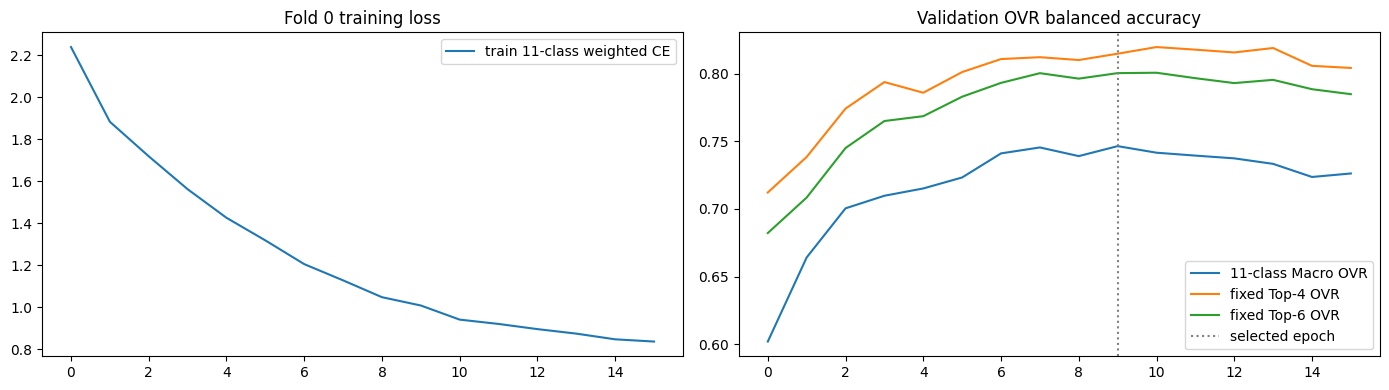

Fold 0 complete. For the next fold set cfg.fold_to_run to 1 and rerun the fold-training cell.


In [10]:
# %% 10 — Run selected fold (one fold per session)
if cfg.fold_to_run < 0 or cfg.fold_to_run >= cfg.n_splits:
    raise IndexError(f'fold_to_run must be in the range 0 to {cfg.n_splits - 1}.')
seed_everything(cfg.seed + cfg.fold_to_run)

if cfg.batch_size * cfg.grad_accum_steps != 16:
    print('WARNING: effective batch is not 16. Keep the same effective batch across all folds if possible.')

# Recreate exactly the same lesion-level five-fold development split as the original setup.
diagnosis_counts = trainval_lesions['class_label'].value_counts()
if diagnosis_counts.min() < 2:
    raise ValueError('At least one diagnosis has fewer than two train+val lesions; reduce folds or revise the split.')
if diagnosis_counts.min() < cfg.n_splits:
    print('NOTE: some rare diagnoses have fewer lesions than the fold count; a validation fold may omit a diagnosis.')

fold_stratify_col = 'class_label'
skf = StratifiedKFold(n_splits=cfg.n_splits, shuffle=True, random_state=cfg.seed)
fold_splits = list(skf.split(trainval_lesions, trainval_lesions[fold_stratify_col]))
train_indices, val_indices = fold_splits[cfg.fold_to_run]
train_lesions = trainval_lesions.iloc[train_indices].reset_index(drop=True)
val_lesions = trainval_lesions.iloc[val_indices].reset_index(drop=True)
assert set(train_lesions['lesion_id']).isdisjoint(set(val_lesions['lesion_id']))

train_samples = build_sample_table(train_lesions, 'train')
val_samples = build_sample_table(val_lesions, 'val')
print(f'Run {RUN_TAG} | Fold {cfg.fold_to_run}: {len(train_samples)} paired training lesions | {len(val_samples)} validation lesions')

(model, history, selected_record, best_epoch, best_path,
 metadata_preprocessor, metadata_preprocessor_path) = train_one_fold(
    train_samples, val_samples, cfg.fold_to_run
)

val_probs_11, val_y_11 = predict_probs_tta(
    model, val_samples, metadata_preprocessor, label_col='label'
)
val_class_scores, val_macro_11, val_top4_11, val_top6_11 = compute_11class_ovr_metrics(
    val_probs_11, val_y_11
)
print('\n=== Selected checkpoint: per-class 11-class OVR balanced accuracy ===')
for class_name in CLASSES:
    score = val_class_scores[class_name]
    print(f'{class_name:<8}: {score:.4f}' if np.isfinite(score) else f'{class_name:<8}: unavailable (class absent)')
print(
    f'\nSelected checkpoint metrics — Macro-11 OVR={val_macro_11:.4f} | '
    f'Fixed Top-4 OVR={val_top4_11:.4f} | Fixed Top-6 OVR={val_top6_11:.4f}'
)
print('\n11-class confusion matrix (rows=true class, columns=predicted class):')
print(confusion_matrix(val_y_11, val_probs_11.argmax(1), labels=np.arange(NUM_CLASSES)))

np.savez(
    os.path.join(MODEL_DIR, f'oof_fold{cfg.fold_to_run}.npz'),
    probs_11=val_probs_11,
    y_11=val_y_11,
)
summary = {
    'run_tag': RUN_TAG,
    'fold': int(cfg.fold_to_run),
    'selected_epoch': int(best_epoch),
    'selected_macro_ovr': float(val_macro_11),
    'selected_top4_ovr': float(val_top4_11),
    'selected_top6_ovr': float(val_top6_11),
    'per_class_ovr_balanced_accuracy': {k: (float(v) if np.isfinite(v) else None) for k, v in val_class_scores.items()},
    'path': best_path,
    'metadata_preprocessor_path': metadata_preprocessor_path,
    'train_stratify': fold_stratify_col,
    'train_lesions': int(len(train_lesions)),
    'val_lesions': int(len(val_lesions)),
    'architecture': 'shared_convnextv2_dual_image_plus_age_site_concatenation_fusion_11class_only',
    'input_size': int(cfg.img_size),
    'backbone': cfg.backbone,
    'metadata_features': ['age_approx', 'site'],
    'regularization': {'dropout': cfg.dropout, 'label_smoothing': cfg.label_smoothing,
                       'weight_decay': cfg.weight_decay},
    'batch_size': int(cfg.batch_size),
    'grad_accum_steps': int(cfg.grad_accum_steps),
    'effective_batch_size': int(cfg.batch_size * cfg.grad_accum_steps),
    'class_weight_power': float(cfg.class_weight_power),
    'training_objective': '11_class_weighted_cross_entropy_only',
    'selection_metric': 'lexicographic_macro11_top6_top4_ovr_balanced_accuracy',
    'selection_priority': ['11_class_macro_ovr_balanced_accuracy', 'fixed_top6_ovr_balanced_accuracy', 'fixed_top4_ovr_balanced_accuracy'],
    'early_stopping_patience': int(cfg.patience),
    'fixed_top4_classes': FIXED_TOP4_CLASSES,
    'fixed_top6_classes': FIXED_TOP6_CLASSES,
    'age_column_in_csv': AGE_META_COL,
    'site_column_in_csv': SITE_META_COL,
    'site_vocabulary_size_including_unknown': metadata_preprocessor.num_site_categories,
}
with open(os.path.join(MODEL_DIR, f'fold{cfg.fold_to_run}_summary.json'), 'w') as file:
    json.dump(summary, file, indent=2)

print(f'\nSaved selected checkpoint: {best_path}')
print(f'Run tag: {RUN_TAG} | model output: {MODEL_DIR}')

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(history['train_loss_11class'], label='train 11-class weighted CE')
axes[0].legend(); axes[0].set_title(f'Fold {cfg.fold_to_run} training loss')
axes[1].plot(history['val_11_macro_ovr'], label='11-class Macro OVR')
axes[1].plot(history['val_11_fixed_top4'], label='fixed Top-4 OVR')
axes[1].plot(history['val_11_fixed_top6'], label='fixed Top-6 OVR')
axes[1].axvline(best_epoch, color='gray', linestyle=':', label='selected epoch')
axes[1].legend(); axes[1].set_title('Validation OVR balanced accuracy')
plt.tight_layout(); plt.show()
print(f'Fold {cfg.fold_to_run} complete. For the next fold set cfg.fold_to_run to {(cfg.fold_to_run + 1) % cfg.n_splits} and rerun the fold-training cell.')


In [11]:
custom_top6_classes = ['BCC', 'NV', 'BKL', 'SCCKA', 'MEL', 'AKIEC']
custom_top6_scores = [val_class_scores[cls] for cls in custom_top6_classes if cls in val_class_scores]
custom_top6_avg = np.mean(custom_top6_scores)

print(f"Custom Top-6 Classes: {custom_top6_classes}")
for cls, score in zip(custom_top6_classes, custom_top6_scores):
    print(f"{cls:<8}: {score:.4f}")
print(f"\nOVR Balanced Accuracy for these 6 classes: {custom_top6_avg:.4f} ({custom_top6_avg * 100:.2f}%)")

Custom Top-6 Classes: ['BCC', 'NV', 'BKL', 'SCCKA', 'MEL', 'AKIEC']
BCC     : 0.8744
NV      : 0.9056
BKL     : 0.7335
SCCKA   : 0.8684
MEL     : 0.7801
AKIEC   : 0.7632

OVR Balanced Accuracy for these 6 classes: 0.8209 (82.09%)


In [12]:
import os
import shutil
import numpy as np
import pandas as pd
from PIL import Image

# 1. Load OOF predictions if they exist
oof_path = os.path.join(MODEL_DIR, f'oof_fold{cfg.fold_to_run}.npz')
if os.path.exists(oof_path):
    data = np.load(oof_path)
    val_probs_11 = data['probs_11']
    val_y_11 = data['y_11']
    val_preds_11 = val_probs_11.argmax(1)

    # 2. Setup output directories for each target confusion type
    confusion_configs = [
        {'true_name': 'BKL', 'pred_name': 'BCC'},
        {'true_name': 'MEL', 'pred_name': 'NV'},
        {'true_name': 'AKIEC', 'pred_name': 'BCC'}
    ]

    confusion_dir = os.path.join(MODEL_DIR, 'confused_images')
    os.makedirs(confusion_dir, exist_ok=True)

    print("Searching for confused samples in Fold 0 Validation Set:")

    # Use val_samples DataFrame which maps directly 1-to-1 with val_probs_11
    for config in confusion_configs:
        true_idx = CLASS_TO_IDX[config['true_name']]
        pred_idx = CLASS_TO_IDX[config['pred_name']]

        # Identify indices matching this specific confusion
        match_mask = (val_y_11 == true_idx) & (val_preds_11 == pred_idx)
        match_indices = np.where(match_mask)[0]

        folder_name = f"true_{config['true_name']}_pred_{config['pred_name']}"
        target_folder = os.path.join(confusion_dir, folder_name)
        os.makedirs(target_folder, exist_ok=True)

        print(f"\nCategory: True {config['true_name']} predicted as {config['pred_name']} -> Found {len(match_indices)} cases.")

        for idx in match_indices[:10]: # Save up to 10 examples per category to avoid bloating disk
            sample_row = val_samples.iloc[idx]
            lesion_id = sample_row['lesion_id']

            # Retrieve the cached image paths
            derm_path = sample_row['derm_cache_path']
            clinical_path = sample_row['clinical_cache_path']

            # Save both views side by side or separately in the confusion directory
            if os.path.exists(derm_path):
                shutil.copy(derm_path, os.path.join(target_folder, f"{lesion_id}_dermoscopic.jpg"))
            if os.path.exists(clinical_path):
                shutil.copy(clinical_path, os.path.join(target_folder, f"{lesion_id}_clinical.jpg"))

        print(f"Saved images for category '{folder_name}' to: {target_folder}")
else:
    print(f"OOF predictions file not found at {oof_path}. Please train Fold 0 first.")

Searching for confused samples in Fold 0 Validation Set:

Category: True BKL predicted as BCC -> Found 24 cases.
Saved images for category 'true_BKL_pred_BCC' to: /content/MILK10k_image_metadata_fusion/models_image_metadata_fusion_pure11_macroovr_img256_cw0.50_b8x2_seed42/confused_images/true_BKL_pred_BCC

Category: True MEL predicted as NV -> Found 17 cases.
Saved images for category 'true_MEL_pred_NV' to: /content/MILK10k_image_metadata_fusion/models_image_metadata_fusion_pure11_macroovr_img256_cw0.50_b8x2_seed42/confused_images/true_MEL_pred_NV

Category: True AKIEC predicted as BCC -> Found 10 cases.
Saved images for category 'true_AKIEC_pred_BCC' to: /content/MILK10k_image_metadata_fusion/models_image_metadata_fusion_pure11_macroovr_img256_cw0.50_b8x2_seed42/confused_images/true_AKIEC_pred_BCC


In [13]:
import os
import shutil
import zipfile
from google.colab import files
import numpy as np
import pandas as pd

# 1. Define paths
target_confusion_dir = '/content/confused_images'
os.makedirs(target_confusion_dir, exist_ok=True)

oof_path = os.path.join(MODEL_DIR, f'oof_fold{cfg.fold_to_run}.npz')
if os.path.exists(oof_path):
    data = np.load(oof_path)
    val_probs_11 = data['probs_11']
    val_y_11 = data['y_11']
    val_preds_11 = val_probs_11.argmax(1)

    confusion_configs = [
        {'true_name': 'BKL', 'pred_name': 'BCC'},
        {'true_name': 'MEL', 'pred_name': 'NV'},
        {'true_name': 'AKIEC', 'pred_name': 'BCC'}
    ]

    for config in confusion_configs:
        true_idx = CLASS_TO_IDX[config['true_name']]
        pred_idx = CLASS_TO_IDX[config['pred_name']]

        match_mask = (val_y_11 == true_idx) & (val_preds_11 == pred_idx)
        match_indices = np.where(match_mask)[0]

        folder_name = f"true_{config['true_name']}_pred_{config['pred_name']}"
        category_folder = os.path.join(target_confusion_dir, folder_name)
        os.makedirs(category_folder, exist_ok=True)

        print(f"Copying {config['true_name']} predicted as {config['pred_name']} ({len(match_indices)} cases)...")
        for idx in match_indices:
            sample_row = val_samples.iloc[idx]
            lesion_id = sample_row['lesion_id']

            derm_path = sample_row['derm_cache_path']
            clinical_path = sample_row['clinical_cache_path']

            if os.path.exists(derm_path):
                shutil.copy(derm_path, os.path.join(category_folder, f"{lesion_id}_dermoscopic.jpg"))
            if os.path.exists(clinical_path):
                shutil.copy(clinical_path, os.path.join(category_folder, f"{lesion_id}_clinical.jpg"))

    # 2. Package everything into a zip file
    zip_output_path = '/content/confused_images.zip'
    print(f"\nZipping files to {zip_output_path}...")
    with zipfile.ZipFile(zip_output_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
        for root, dirs, files_list in os.walk(target_confusion_dir):
            for filename in files_list:
                file_path = os.path.join(root, filename)
                zipf.write(file_path, os.path.relpath(file_path, '/content'))

    print("Triggering file download...")
    files.download(zip_output_path)
else:
    print("OOF predictions file not found. Please train Fold 0 first.")

Copying BKL predicted as BCC (24 cases)...
Copying MEL predicted as NV (17 cases)...
Copying AKIEC predicted as BCC (10 cases)...

Zipping files to /content/confused_images.zip...
Triggering file download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
import os
import numpy as np
import pandas as pd

oof_path = os.path.join(MODEL_DIR, f'oof_fold{cfg.fold_to_run}.npz')
if os.path.exists(oof_path):
    data = np.load(oof_path)
    val_probs_11 = data['probs_11']
    val_y_11 = data['y_11']
    val_preds_11 = val_probs_11.argmax(1)

    print("--- DIAGNOSTIC CHECK ---")
    print(f"OOF Loaded from: {oof_path}")
    print(f"Total validation size in OOF predictions: {len(val_y_11)}")
    print(f"Total validation size in val_samples: {len(val_samples)}")

    # Verification of specific errors
    configs = [
        {'true_name': 'BKL', 'pred_name': 'BCC', 'true_idx': CLASS_TO_IDX['BKL'], 'pred_idx': CLASS_TO_IDX['BCC']},
        {'true_name': 'MEL', 'pred_name': 'NV', 'true_idx': CLASS_TO_IDX['MEL'], 'pred_idx': CLASS_TO_IDX['NV']},
        {'true_name': 'AKIEC', 'pred_name': 'BCC', 'true_idx': CLASS_TO_IDX['AKIEC'], 'pred_idx': CLASS_TO_IDX['BCC']}
    ]

    for config in configs:
        true_mask = (val_y_11 == config['true_idx'])
        pred_mask = (val_preds_11 == config['pred_idx'])
        confused_mask = true_mask & pred_mask
        match_indices = np.where(confused_mask)[0]

        # Extract unique lesion IDs from matching indices
        matched_lesions = val_samples.iloc[match_indices]['lesion_id'].tolist()
        unique_lesions = list(set(matched_lesions))

        print(f"\nCategory: {config['true_name']} (class {config['true_idx']}) predicted as {config['pred_name']} (class {config['pred_idx']})")
        print(f"  Count from confusion matrix arrays: {np.sum(confused_mask)}")
        print(f"  Number of unique lesion_ids copied: {len(unique_lesions)}")
        if len(unique_lesions) != len(match_indices):
            print(f"  Warning: Duplicate lesion_ids present in val_samples indices! (Duplicates: {len(match_indices) - len(unique_lesions)})")
else:
    print("OOF predictions file not found.")

--- DIAGNOSTIC CHECK ---
OOF Loaded from: /content/MILK10k_image_metadata_fusion/models_image_metadata_fusion_pure11_macroovr_img256_cw0.50_b8x2_seed42/oof_fold0.npz
Total validation size in OOF predictions: 944
Total validation size in val_samples: 944

Category: BKL (class 3) predicted as BCC (class 1)
  Count from confusion matrix arrays: 24
  Number of unique lesion_ids copied: 24

Category: MEL (class 7) predicted as NV (class 8)
  Count from confusion matrix arrays: 17
  Number of unique lesion_ids copied: 17

Category: AKIEC (class 0) predicted as BCC (class 1)
  Count from confusion matrix arrays: 10
  Number of unique lesion_ids copied: 10


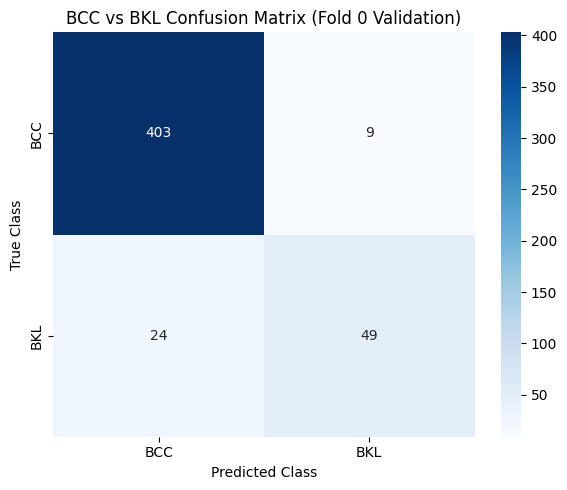

Total true BKL samples in validation: 98
BKL predicted as BCC: 24
BCC predicted as BKL: 9


In [15]:
import numpy as np
import os
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Load the out-of-fold validation predictions
oof_path = os.path.join(MODEL_DIR, f'oof_fold{cfg.fold_to_run}.npz')
if os.path.exists(oof_path):
    data = np.load(oof_path)
    val_probs_11 = data['probs_11']
    val_y_11 = data['y_11']
    val_preds_11 = val_probs_11.argmax(1)

    # Target classes: BCC (idx 1) and BKL (idx 3)
    target_idxs = [1, 3]
    target_labels = ['BCC', 'BKL']

    # Filter validation set to contain only ground truth BCC or BKL
    mask = np.isin(val_y_11, target_idxs)
    filtered_y = val_y_11[mask]
    filtered_preds = val_preds_11[mask]

    # Map predictions that fell outside of BCC/BKL to 'Other' to maintain realistic context,
    # or compute a direct 2x2 confusion matrix for samples belonging to these two classes.
    # Let's compute the direct 2x2 confusion matrix of BCC vs BKL for maximum clarity:
    cm_2x2 = confusion_matrix(filtered_y, filtered_preds, labels=target_idxs)

    plt.figure(figsize=(6, 5))
    sns.heatmap(cm_2x2, annot=True, fmt='d', cmap='Blues',
                xticklabels=target_labels, yticklabels=target_labels, cbar=True)
    plt.title('BCC vs BKL Confusion Matrix (Fold 0 Validation)')
    plt.ylabel('True Class')
    plt.xlabel('Predicted Class')
    plt.tight_layout()
    plt.show()

    # Print out detailed breakdown
    bkl_idx = CLASS_TO_IDX['BKL']
    bcc_idx = CLASS_TO_IDX['BCC']
    bkl_as_bcc = np.sum((val_y_11 == bkl_idx) & (val_preds_11 == bcc_idx))
    bcc_as_bkl = np.sum((val_y_11 == bcc_idx) & (val_preds_11 == bkl_idx))
    print(f"Total true BKL samples in validation: {np.sum(val_y_11 == bkl_idx)}")
    print(f"BKL predicted as BCC: {bkl_as_bcc}")
    print(f"BCC predicted as BKL: {bcc_as_bkl}")
else:
    print(f"OOF predictions not found at {oof_path}. Please make sure to run the training fold first.")

## Grad-CAM error analysis (Fold 0 validation)

The next cells explain the **selected Fold 0 checkpoint** on the validation lesions. They only need the objects already in memory after cells 4–10 (`val_samples`, `val_tf`, `metadata_preprocessor`, `MODEL_DIR`) plus the saved `oof_fold0.npz` and `…_best.pt`.

| Cell | What it does |
|---|---|
| G1 | Selects the cases: MEL→NV, BKL→BCC, AKIEC→BCC errors and correctly classified MEL / NV / BKL / AKIEC controls |
| G2 | Reloads the best checkpoint, runs Grad-CAM for **both views in one pass** (shared encoder), target = predicted class (and true class for errors) |
| G3 | Heuristic lesion-vs-skin mask and CAM-location metrics (lesion focus, colour-atypical core, texture, asymmetry) |
| G4 | Figure helpers: dermoscopic + overlay, clinical + overlay, side-by-side (predicted-class CAM, and true-class CAM for errors) |
| G5 | Shows the galleries inline and saves three PNGs per case |
| G6 | Computes the metrics and shows lesion-mask quality control |
| G7 | Summary tables, group-mean heat maps, cross-group similarity, evidence printout |
| G8 | Optional zip download |

**Read before interpreting**
- Grad-CAM at the last ConvNeXt stage is an **8×8 map upsampled to 256 px**: it shows coarse regions, not borders or individual dermoscopic structures. Set `GC_STAGE = -2` for a 16×16 map.
- Age/site metadata is also fused into the logits; Grad-CAM explains only the image part.
- The lesion mask is a colour-distance heuristic, not a validated segmentation; check the mask QC figure before trusting the lesion-focus numbers.
- Asymmetry/texture figures are **proxies** computed from the mask and the CLAHE-processed cached image. Subgroup sizes (10–24 cases) are small, so treat comparisons as exploratory.
- Images are shown exactly as the model saw them (short-edge resize + centre crop), so peripheral skin may be cropped.

In [16]:
# %% G1 — Grad-CAM setup: choose error cases and correctly classified controls
from scipy import ndimage as ndi
from scipy.stats import mannwhitneyu
from IPython.display import display

# ---- configuration --------------------------------------------------------
ERROR_GROUPS = [('MEL', 'NV'), ('BKL', 'BCC'), ('AKIEC', 'BCC')]          # (true, predicted)
EXPECTED_COUNTS = {('MEL', 'NV'): 17, ('BKL', 'BCC'): 24, ('AKIEC', 'BCC'): 10}
CORRECT_CLASSES = ['MEL', 'NV', 'BKL', 'AKIEC']   # add 'BCC' to also compare the two BCC-predicted error groups with true BCC
N_CORRECT_PER_CLASS = 20                          # seeded random sample per class; None = use every correct case
GC_STAGE = -1                                     # -1: last stage (8x8 map at 256 px); -2: stage 3 (16x16, finer, less class-specific)
GC_SEED = 42
SHOW_N = 6                                        # cases shown inline per group and view (all cases are saved to disk)

GC_DIR = os.path.join(MODEL_DIR, f'gradcam_fold{cfg.fold_to_run}')
os.makedirs(GC_DIR, exist_ok=True)

# ---- TTA-averaged OOF predictions: the same ones behind the reported confusion matrix ----
oof_path = os.path.join(MODEL_DIR, f'oof_fold{cfg.fold_to_run}.npz')
assert os.path.exists(oof_path), 'oof file missing - train/evaluate the fold first.'
_oof = np.load(oof_path)
gc_probs, gc_y = _oof['probs_11'], _oof['y_11']
gc_pred = gc_probs.argmax(1)
assert len(gc_y) == len(val_samples) and np.array_equal(gc_y, val_samples['label'].to_numpy()), (
    'OOF rows do not line up with val_samples. Rebuild val_samples for this fold (cell 10 split) before running.')

GROUP_ORDER = [f'{t}→{p}' for t, p in ERROR_GROUPS] + [f'correct {c}' for c in CORRECT_CLASSES]
rng = np.random.default_rng(GC_SEED)
case_rows = []
for t, p in ERROR_GROUPS:
    idx = np.where((gc_y == CLASS_TO_IDX[t]) & (gc_pred == CLASS_TO_IDX[p]))[0]
    exp = EXPECTED_COUNTS.get((t, p))
    note = '' if exp is None or exp == len(idx) else f'   <-- expected {exp}, check fold / checkpoint'
    print(f'{t}→{p:<6}: {len(idx)} error cases{note}')
    case_rows += [dict(group=f'{t}→{p}', kind='error', true=t, pred=p, row=int(i)) for i in idx]
for c in CORRECT_CLASSES:
    idx = np.where((gc_y == CLASS_TO_IDX[c]) & (gc_pred == CLASS_TO_IDX[c]))[0]
    n_all = len(idx)
    if N_CORRECT_PER_CLASS is not None and n_all > N_CORRECT_PER_CLASS:
        idx = np.sort(rng.choice(idx, N_CORRECT_PER_CLASS, replace=False))
    print(f'correct {c:<5}: using {len(idx)} of {n_all} correctly classified')
    case_rows += [dict(group=f'correct {c}', kind='correct', true=c, pred=c, row=int(i)) for i in idx]

gc_cases = pd.DataFrame(case_rows)
rows_ = gc_cases['row'].to_numpy()
gc_cases['lesion_id'] = val_samples['lesion_id'].to_numpy()[rows_]
gc_cases['oof_p_pred'] = gc_probs[rows_, gc_cases['pred'].map(CLASS_TO_IDX).to_numpy()]
gc_cases['oof_p_true'] = gc_probs[rows_, gc_cases['true'].map(CLASS_TO_IDX).to_numpy()]
print(f'\nTotal Grad-CAM cases: {len(gc_cases)} | output folder: {GC_DIR}')

MEL→NV    : 17 error cases
BKL→BCC   : 24 error cases
AKIEC→BCC   : 10 error cases
correct MEL  : using 20 of 48 correctly classified
correct NV   : using 20 of 114 correctly classified
correct BKL  : using 20 of 49 correctly classified
correct AKIEC: using 20 of 30 correctly classified

Total Grad-CAM cases: 131 | output folder: /content/MILK10k_image_metadata_fusion/models_image_metadata_fusion_pure11_macroovr_img256_cw0.50_b8x2_seed42/gradcam_fold0


In [17]:
# %% G2 — Grad-CAM engine: reload the selected checkpoint and explain every case (both views per pass)
_prep_json = os.path.join(MODEL_DIR, f'MILK10k_image_metadata_fold{cfg.fold_to_run}_preprocessor.json')
gc_prep = metadata_preprocessor if 'metadata_preprocessor' in globals() else \
    MetadataPreprocessor.from_state_dict(json.load(open(_prep_json)))
_best_ckpt = os.path.join(MODEL_DIR, f'MILK10k_image_metadata_fold{cfg.fold_to_run}_best.pt')

gc_model = DualImageMetadataConvNeXtV2(NUM_CLASSES, gc_prep.num_site_categories, cfg.backbone, pretrained=False)
gc_model.load_state_dict(torch.load(_best_ckpt, map_location='cpu', weights_only=True))
gc_model.to(DEVICE).eval()
if hasattr(gc_model.encoder, 'set_grad_checkpointing'):
    gc_model.encoder.set_grad_checkpointing(False)     # checkpointing re-runs the forward pass and breaks activation hooks
for prm in gc_model.parameters():
    prm.requires_grad_(False)                          # gradients flow to the *inputs* only; no parameter grads needed


class DualViewGradCAM:
    """Grad-CAM on one ConvNeXtV2 stage. The model stacks [dermoscopic; clinical] into a single encoder batch,
    so one forward/backward gives a separate CAM for each view (row 0 = dermoscopic, row 1 = clinical)."""
    def __init__(self, model, stage=-1):
        self.model, self.act, self.grad = model, None, None
        model.encoder.stages[stage].register_forward_hook(self._save)

    def _save(self, module, args, out):
        self.act = out.detach()
        out.register_hook(lambda g: setattr(self, 'grad', g.detach()))

    def run(self, derm, clin, age, site, targets):
        """derm/clin: (1,3,S,S) with requires_grad=True. Returns ({class_idx: (cam_derm, cam_clin)}, softmax probs)."""
        cams, probs = {}, None
        for tgt in targets:
            with torch.enable_grad():
                logits = self.model(derm, clin, age, site)
                if probs is None:
                    probs = logits.detach().float().softmax(1)[0].cpu().numpy()
                logits[0, tgt].backward()
            weights = self.grad.mean(dim=(2, 3), keepdim=True)                 # (2, C, 1, 1)
            cam = F.relu((weights * self.act).sum(1, keepdim=True))            # (2, 1, h, w)
            cam = F.interpolate(cam, size=(S, S), mode='bilinear', align_corners=False)[:, 0]
            cams[tgt] = (cam[0].cpu().numpy(), cam[1].cpu().numpy())
        return cams, probs


def denorm_u8(tensor):
    mean = torch.tensor(MEAN)[:, None, None]
    std = torch.tensor(STD)[:, None, None]
    return ((tensor.detach().cpu() * std + mean).clamp(0, 1).permute(1, 2, 0).numpy() * 255).astype(np.uint8)


def load_case_tensors(row):
    sample = val_samples.iloc[row]
    with Image.open(sample['derm_cache_path']) as image:
        derm = val_tf(image.convert('RGB'))               # same eval geometry as validation: resize short edge + centre crop
    with Image.open(sample['clinical_cache_path']) as image:
        clin = val_tf(image.convert('RGB'))
    age, site = gc_prep.transform(val_samples.iloc[[row]])
    return derm, clin, torch.tensor(age), torch.tensor(site)


gradcam = DualViewGradCAM(gc_model, GC_STAGE)
gc_records = {}
for _, case in tqdm(gc_cases.iterrows(), total=len(gc_cases), desc='Grad-CAM'):
    row, pred_idx, true_idx = int(case['row']), CLASS_TO_IDX[case['pred']], CLASS_TO_IDX[case['true']]
    derm, clin, age, site = load_case_tensors(row)
    targets = [pred_idx] + ([true_idx] if case['kind'] == 'error' else [])
    cams, probs = gradcam.run(derm[None].to(DEVICE).requires_grad_(True), clin[None].to(DEVICE).requires_grad_(True),
                              age.to(DEVICE), site.to(DEVICE), targets)
    cam_true = cams[true_idx]
    gc_records[(case['group'], case['lesion_id'])] = dict(
        group=case['group'], kind=case['kind'], true=case['true'], pred=case['pred'], lesion_id=case['lesion_id'], row=row,
        oof_p_pred=float(case['oof_p_pred']), oof_p_true=float(case['oof_p_true']),
        sp_probs=probs, sp_pred_matches=bool(int(probs.argmax()) == pred_idx),
        site=val_samples.iloc[row]['site'], age=float(val_samples.iloc[row]['age_approx']),
        derm=denorm_u8(derm), clin=denorm_u8(clin),
        cam_pred_derm=cams[pred_idx][0], cam_pred_clin=cams[pred_idx][1],
        cam_true_derm=cam_true[0], cam_true_clin=cam_true[1],
    )

n_mismatch = sum(not r['sp_pred_matches'] for r in gc_records.values())
n_empty = sum(float(r['cam_pred_derm'].max()) <= 0 or float(r['cam_pred_clin'].max()) <= 0 for r in gc_records.values())
print(f'{len(gc_records)} cases explained.')
print(f'Single un-augmented pass disagrees with the TTA prediction in {n_mismatch} case(s) (Grad-CAM always explains the TTA-predicted class).')
print(f'Cases with an all-zero CAM in at least one view: {n_empty}')

Grad-CAM:   0%|          | 0/131 [00:00<?, ?it/s]

131 cases explained.
Single un-augmented pass disagrees with the TTA prediction in 4 case(s) (Grad-CAM always explains the TTA-predicted class).
Cases with an all-zero CAM in at least one view: 0


In [18]:
# %% G3 — Heuristic lesion mask + CAM-location metrics (numpy/OpenCV only)
METRIC_KEYS = ['lesion_energy', 'focus_ratio', 'peak_in_lesion', 'top20_in_lesion', 'area50', 'centroid_offset',
               'core_enrichment', 'texture_enrichment', 'shape_asym', 'color_asym', 'cam_share_atypical_half']


def lesion_mask(img_u8):
    """Rough lesion / surrounding-skin split: LAB colour distance from the 'background' colour (median of the outer
    image ring, black vignette ignored) -> Otsu -> clean-up -> component closest to the centre.
    Returns (mask, colour-distance map, ok). NOT a validated segmentation: inspect show_mask_qc() and keep mask_ok."""
    lab = cv2.cvtColor(img_u8, cv2.COLOR_RGB2LAB).astype(np.float32)
    h, w = lab.shape[:2]
    black = lab[..., 0] < 30                                   # near-black pixels (OpenCV L scale 0-255)
    bl, nb = ndi.label(black)
    border_ids = np.unique(np.concatenate([bl[0], bl[-1], bl[:, 0], bl[:, -1]]))
    vignette = ndi.binary_dilation(np.isin(bl, border_ids[border_ids > 0]), iterations=2) if nb else np.zeros_like(black)
    valid = ~vignette                                          # drops only border-connected black (dermoscope vignette / padding)
    yy, xx = np.mgrid[:h, :w]
    edge = np.minimum.reduce([yy, xx, h - 1 - yy, w - 1 - xx])
    ring = (edge < 0.12 * min(h, w)) & valid
    if ring.sum() < 200:
        ring = valid if valid.sum() >= 200 else np.ones_like(valid)
    bg = np.median(lab[ring], axis=0)
    dE = cv2.GaussianBlur(np.linalg.norm(lab - bg, axis=2), (0, 0), 2)
    dE[~valid] = 0
    d8 = np.clip(255 * dE / (dE.max() + 1e-6), 0, 255).astype(np.uint8)
    _, m = cv2.threshold(d8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    m = ndi.binary_fill_holes(ndi.binary_closing(ndi.binary_opening(m > 0, iterations=2), iterations=3))
    lbl, n = ndi.label(m)
    ok = False
    if n > 0:
        idx = np.arange(1, n + 1)
        areas = ndi.sum(m, lbl, index=idx)
        cents = np.array(ndi.center_of_mass(m, lbl, index=idx)).reshape(-1, 2)
        dist = np.hypot(cents[:, 0] - h / 2, cents[:, 1] - w / 2) / (0.3 * min(h, w))
        best = int(np.argmax(areas / (1 + dist ** 2)))
        m = lbl == (1 + best)
        # reject empty/huge masks, masks running into the image border, and low-contrast masks (background mistaken for lesion)
        hugs_border = (m & (edge < 0.08 * min(h, w))).sum() / m.sum() >= 0.35
        ok = (0.02 <= m.mean() <= 0.90) and dist[best] < 1.6 and not hugs_border
        if ok:                                                 # lesion must differ clearly in colour from the skin around it
            inside, outside = dE[m].mean(), dE[~m & valid].mean() if (~m & valid).any() else 0.0
            ok = inside >= 12 and inside >= 2.0 * outside
    if not ok:                                                 # fall back to a central ellipse and flag it
        m = ((yy - h / 2) / (0.30 * h)) ** 2 + ((xx - w / 2) / (0.30 * w)) ** 2 <= 1
    return m, dE, bool(ok)


def local_texture(gray, k=7):
    mu, sq = cv2.blur(gray, (k, k)), cv2.blur(gray * gray, (k, k))
    return np.sqrt(np.maximum(sq - mu * mu, 0))


def _principal_frame(mask):
    ys, xs = np.nonzero(mask)
    pts = np.stack([xs - xs.mean(), ys - ys.mean()], 1).astype(np.float64)
    _, vecs = np.linalg.eigh(np.cov(pts.T))
    return ys, xs, pts @ vecs                                  # uv[:,0] = minor axis, uv[:,1] = major axis


def shape_asymmetry(mask):
    """1 - mean IoU of the lesion mask with its mirror images about the two principal axes (0 = symmetric)."""
    if mask.sum() < 50:
        return np.nan
    _, _, uv = _principal_frame(mask)
    R = int(np.ceil(np.abs(uv).max())) + 2
    g = np.zeros((2 * R + 1, 2 * R + 1), bool)
    g[np.rint(uv[:, 1]).astype(int) + R, np.rint(uv[:, 0]).astype(int) + R] = True
    g = ndi.binary_closing(g, structure=np.ones((3, 3)))
    iou = lambda a, b: (a & b).sum() / max((a | b).sum(), 1)
    return float(1.0 - 0.5 * (iou(g, g[::-1, :]) + iou(g, g[:, ::-1])))


def cam_metrics(img_u8, cam, mask, dE):
    """Where does this CAM put its mass? p = CAM normalised to sum 1 (per image, so magnitudes are not compared).
    focus_ratio      CAM mass inside lesion / lesion area fraction (1 = no preference, >1 = lesion-centred, <1 = skin-centred)
    top20_in_lesion  share of the strongest 20 % CAM pixels that fall inside the lesion
    area50           fraction of the image needed to hold 50 % of the CAM mass (small = tightly focused)
    core_enrichment  CAM density on the 25 % most colour-atypical lesion pixels vs the rest of the lesion (>1 = favours it)
    texture_enrichment  CAM-weighted local texture inside the lesion / mean lesion texture (>1 = favours rough areas)
    shape_asym / color_asym   lesion shape / colour asymmetry about its principal axes (proxies)
    cam_share_atypical_half   share of in-lesion CAM mass on the more colour-atypical half (0.5 = no preference)"""
    out = dict.fromkeys(METRIC_KEYS, np.nan)
    p = np.maximum(cam.astype(np.float64), 0)
    if p.sum() < 1e-12 or mask.sum() < 50:
        return out
    p /= p.sum()
    h, w = p.shape
    yy, xx = np.mgrid[:h, :w]
    in_mass = p[mask].sum()
    out['lesion_energy'] = in_mass
    out['focus_ratio'] = in_mass / mask.mean()
    out['peak_in_lesion'] = float(mask[np.unravel_index(np.argmax(p), p.shape)])
    k = max(1, int(0.2 * p.size))
    top = np.zeros(p.size, bool)
    top[np.argpartition(p.ravel(), -k)[-k:]] = True
    out['top20_in_lesion'] = float((top.reshape(p.shape) & mask).sum() / k)
    out['area50'] = (np.searchsorted(np.cumsum(np.sort(p.ravel())[::-1]), 0.5) + 1) / p.size
    out['centroid_offset'] = np.hypot((p * yy).sum() - yy[mask].mean(), (p * xx).sum() - xx[mask].mean()) / max(h, w)

    if in_mass > 1e-12:
        core = mask & (dE >= np.quantile(dE[mask], 0.75))
        if 0 < core.sum() < mask.sum():
            out['core_enrichment'] = (p[core].sum() / in_mass) / (core.sum() / mask.sum())
        tex = local_texture(cv2.cvtColor(img_u8, cv2.COLOR_RGB2LAB)[..., 0].astype(np.float32))
        out['texture_enrichment'] = ((p[mask] * tex[mask]).sum() / in_mass) / (tex[mask].mean() + 1e-6)

    out['shape_asym'] = shape_asymmetry(mask)
    ys, xs, uv = _principal_frame(mask)
    dev, pm, best = dE[ys, xs], p[ys, xs], None
    for axis in (0, 1):                                        # split the lesion across each principal axis
        half = uv[:, axis] > 0
        if half.sum() >= 20 and (~half).sum() >= 20:
            diff = abs(dev[half].mean() - dev[~half].mean())
            if best is None or diff > best[0]:
                best = (diff, half)
    if best is not None:
        diff, half = best
        out['color_asym'] = diff / (dev.mean() + 1e-6)
        atypical = half if dev[half].mean() >= dev[~half].mean() else ~half
        if pm.sum() > 1e-12:
            out['cam_share_atypical_half'] = pm[atypical].sum() / pm.sum()
    return out

In [19]:
# %% G4 — Visual explanations: dermoscopic overlay, clinical overlay, side-by-side (inline + saved PNGs)
VIEW_NAME = {'derm': 'Dermoscopic', 'clin': 'Clinical'}


def heat_overlay(img_u8, cam, alpha=0.45):
    c = cam / (cam.max() + 1e-8)                               # per-image min-max for display only
    heat = cv2.applyColorMap((255 * c).astype(np.uint8), cv2.COLORMAP_JET)[..., ::-1]
    return ((1 - alpha) * img_u8 + alpha * heat).astype(np.uint8)


def _case_title(rec):
    meta = f"{rec['site']}, " + (f"age {rec['age']:.0f}" if np.isfinite(rec['age']) else 'age n/a')
    if rec['kind'] == 'error':
        return f"{rec['lesion_id']} | true {rec['true']} -> predicted {rec['pred']} (p={rec['oof_p_pred']:.2f}, p_true={rec['oof_p_true']:.2f}) | {meta}"
    return f"{rec['lesion_id']} | correct {rec['true']} (p={rec['oof_p_pred']:.2f}) | {meta}"


def _blank(ax):
    ax.set_xticks([]); ax.set_yticks([])


def draw_view_row(axes_row, rec, view):
    ax = axes_row
    ax[0].imshow(rec[view]); ax[0].set_title(f"{rec['lesion_id']}\n{VIEW_NAME[view]}", fontsize=7)
    ax[1].imshow(heat_overlay(rec[view], rec[f'cam_pred_{view}']))
    ax[1].set_title(f"Grad-CAM -> {rec['pred']}" + (' (predicted)' if rec['kind'] == 'error' else ''), fontsize=7)
    if len(ax) > 2:
        if rec['kind'] == 'error':
            ax[2].imshow(heat_overlay(rec[view], rec[f'cam_true_{view}']))
            ax[2].set_title(f"Grad-CAM -> {rec['true']} (true)", fontsize=7)
    for a in ax:
        _blank(a)


def montage_view(recs, view):
    ncols = 3 if any(r['kind'] == 'error' for r in recs) else 2
    fig, axes = plt.subplots(len(recs), ncols, figsize=(2.8 * ncols, 2.9 * len(recs)), squeeze=False)
    for axes_row, rec in zip(axes, recs):
        draw_view_row(axes_row, rec, view)
    fig.tight_layout()
    return fig


def fig_side_by_side(rec):
    rows = [('pred', rec['pred'])] + ([('true', rec['true'])] if rec['kind'] == 'error' else [])
    fig, axes = plt.subplots(len(rows), 4, figsize=(11, 2.9 * len(rows) + 0.6), squeeze=False)
    for r, (which, name) in enumerate(rows):
        for j, view in enumerate(('derm', 'clin')):
            axes[r, 2 * j].imshow(rec[view])
            axes[r, 2 * j + 1].imshow(heat_overlay(rec[view], rec[f'cam_{which}_{view}']))
            if r == 0:
                axes[r, 2 * j].set_title(VIEW_NAME[view], fontsize=9)
                axes[r, 2 * j + 1].set_title('Grad-CAM', fontsize=9)
        tag = ' (predicted)' if (which == 'pred' and rec['kind'] == 'error') else (' (true)' if which == 'true' else '')
        axes[r, 0].set_ylabel(f'target: {name}{tag}', fontsize=8)
    for a in axes.ravel():
        _blank(a)
    fig.suptitle(_case_title(rec), fontsize=9)
    fig.tight_layout()
    return fig


def _safe(text):
    return re.sub(r'[^A-Za-z0-9]+', '_', text).strip('_')


def save_all_figures(dpi=130):
    for rec in gc_records.values():
        folder = os.path.join(GC_DIR, _safe(rec['group']))
        os.makedirs(folder, exist_ok=True)
        for tag, fig in (('dermoscopic_gradcam', montage_view([rec], 'derm')),
                         ('clinical_gradcam', montage_view([rec], 'clin')),
                         ('side_by_side', fig_side_by_side(rec))):
            fig.savefig(os.path.join(folder, f"{rec['lesion_id']}_{tag}.png"), dpi=dpi, bbox_inches='tight')
            plt.close(fig)
    print(f'Saved 3 PNGs per case under {GC_DIR}')


def show_gallery(group, view='derm', start=0, n=None):
    """view: 'derm' | 'clin' | 'both' (side-by-side). Shows cases start .. start+n of one group."""
    n = n or SHOW_N
    recs = [r for r in gc_records.values() if r['group'] == group][start:start + n]
    if not recs:
        print(f'No cases for {group}'); return
    print(f'=== {group} | {VIEW_NAME.get(view, "Dermoscopic + clinical")} | cases {start + 1}-{start + len(recs)} ===')
    if view == 'both':
        figs = [fig_side_by_side(rec) for rec in recs]
    else:
        figs = [montage_view(recs, view)]
    for fig in figs:
        plt.show(); plt.close(fig)

In [ ]:
# %% G5 — Inline galleries (errors first, then correctly classified controls) + save every case as PNG
# Per group: (1) dermoscopic + Grad-CAM, (2) clinical + Grad-CAM, (3) side-by-side of both views.
# Error rows also show the CAM for the TRUE class ("what would have supported the right answer?").
# Use show_gallery('BKL→BCC', 'derm', start=6) to page through the remaining cases of a group.
for group in GROUP_ORDER:
    for view in ('derm', 'clin', 'both'):
        show_gallery(group, view)
save_all_figures()

In [23]:
import os
import shutil
from google.colab import files

target_dir = '/content/MILK10k_image_metadata_fusion/models_image_metadata_fusion_pure11_macroovr_img256_cw0.50_b8x2_seed42/gradcam_fold0'
output_zip = '/content/gradcam_fold0_download'

if os.path.exists(target_dir):
    print(f"Zipping {target_dir}...")
    zip_path = shutil.make_archive(output_zip, 'zip', target_dir)
    print(f"Created archive: {zip_path}")
    print("Triggering download...")
    files.download(zip_path)
else:
    print(f"Error: Directory not found at {target_dir}")

Zipping /content/MILK10k_image_metadata_fusion/models_image_metadata_fusion_pure11_macroovr_img256_cw0.50_b8x2_seed42/gradcam_fold0...
Created archive: /content/gradcam_fold0_download.zip
Triggering download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# %% G6 — Lesion masks, CAM-location metrics and mask quality control
def compute_all_metrics():
    rows = []
    for rec in gc_records.values():
        for view in ('derm', 'clin'):
            mask, dE, ok = lesion_mask(rec[view])
            rec[f'mask_{view}'], rec[f'dE_{view}'], rec[f'mask_ok_{view}'] = mask, dE, ok
            for which in (('pred', 'true') if rec['kind'] == 'error' else ('pred',)):
                rows.append(dict(group=rec['group'], kind=rec['kind'], lesion_id=rec['lesion_id'], view=view,
                                 target=which, mask_ok=ok, **cam_metrics(rec[view], rec[f'cam_{which}_{view}'], mask, dE)))
    return pd.DataFrame(rows)


def show_mask_qc(n=12, seed=0):
    """Yellow contour = heuristic lesion mask. '[fallback]' = mask failed checks and a central ellipse was used."""
    keys = list(gc_records)
    pick = np.random.default_rng(seed).choice(len(keys), min(n, len(keys)), replace=False)
    fig, axes = plt.subplots(2, len(pick), figsize=(2.1 * len(pick), 4.8), squeeze=False)
    for j, k in enumerate(pick):
        rec = gc_records[keys[k]]
        for i, view in enumerate(('derm', 'clin')):
            ax = axes[i, j]
            ax.imshow(rec[view])
            ax.contour(rec[f'mask_{view}'].astype(float), levels=[0.5], colors='yellow', linewidths=1.2)
            ax.set_title(f"{rec['group']}\n{VIEW_NAME[view][:5]}" + ('' if rec[f'mask_ok_{view}'] else ' [fallback]'), fontsize=6)
            _blank(ax)
    fig.tight_layout(); plt.show()


gc_metrics = compute_all_metrics()
gc_metrics.to_csv(os.path.join(GC_DIR, 'gradcam_metrics.csv'), index=False)
print('Share of cases where the heuristic lesion mask passed its checks (mask_ok):')
display(gc_metrics[gc_metrics.target == 'pred'].groupby(['group', 'view'])['mask_ok'].mean().unstack().reindex(GROUP_ORDER).round(2))
show_mask_qc(n=12, seed=0)
show_mask_qc(n=12, seed=1)

In [ ]:
# %% G7 — Summary analysis: where does the model look, and is it the same place across errors?
ONLY_MASK_OK = True            # drop views whose lesion mask fell back to the central ellipse
SUMMARY_KEYS = ['focus_ratio', 'lesion_energy', 'top20_in_lesion', 'peak_in_lesion', 'area50', 'centroid_offset',
                'core_enrichment', 'texture_enrichment', 'cam_share_atypical_half']

pm = gc_metrics[gc_metrics.target == 'pred'].copy()
if ONLY_MASK_OK:
    print(f'Dropping {(~pm.mask_ok).sum()} of {len(pm)} case-views with a failed mask (set ONLY_MASK_OK=False to keep them).')
    pm = pm[pm.mask_ok]


def med_iqr(s):
    s = s.dropna()
    return f'{s.median():.2f} [{s.quantile(.25):.2f}-{s.quantile(.75):.2f}]' if len(s) else '-'


# ---- Table A: per group and view ----------------------------------------------------------------
agg = {k: med_iqr for k in SUMMARY_KEYS}
agg['peak_in_lesion'] = lambda s: f'{s.dropna().mean():.0%}' if s.notna().any() else '-'
table_a = pm.groupby(['view', 'group']).agg(agg)
table_a.insert(0, 'n', pm.groupby(['view', 'group']).size())
table_a = table_a.loc[[(v, g) for v in ('derm', 'clin') for g in GROUP_ORDER if (v, g) in table_a.index]]
print('\nTable A — median [IQR] per group (peak_in_lesion = % of cases whose CAM maximum lies inside the lesion mask)')
display(table_a)
table_a.to_csv(os.path.join(GC_DIR, 'summary_table_A.csv'))

# ---- Table B: each error group vs its correctly classified references ----------------------------
COMPARISONS = [('MEL→NV', 'correct MEL'), ('MEL→NV', 'correct NV'), ('BKL→BCC', 'correct BKL'),
               ('BKL→BCC', 'correct BCC'), ('AKIEC→BCC', 'correct AKIEC'), ('AKIEC→BCC', 'correct BCC')]
B_KEYS = ['focus_ratio', 'area50', 'core_enrichment', 'texture_enrichment', 'cam_share_atypical_half']
rows = []
for view in ('derm', 'clin'):
    for a, b in COMPARISONS:
        for key in B_KEYS:
            xa = pm[(pm.view == view) & (pm.group == a)][key].dropna()
            xb = pm[(pm.view == view) & (pm.group == b)][key].dropna()
            if len(xa) >= 3 and len(xb) >= 3:
                rows.append(dict(view=view, error_group=a, reference=b, metric=key, n_err=len(xa), n_ref=len(xb),
                                 median_err=xa.median(), median_ref=xb.median(),
                                 p_mwu=mannwhitneyu(xa, xb, alternative='two-sided').pvalue))
table_b = pd.DataFrame(rows)
print('\nTable B — error group vs correct reference (Mann-Whitney U, two-sided, UNCORRECTED p; exploratory, n is small)')
if len(table_b):
    display(table_b.round(3))
    table_b.to_csv(os.path.join(GC_DIR, 'summary_table_B.csv'), index=False)


# ---- Group-mean CAMs and cross-group similarity --------------------------------------------------
def _small(cam, size=32):
    return cv2.resize((cam / (cam.max() + 1e-8)).astype(np.float32), (size, size), interpolation=cv2.INTER_AREA)


def _pearson(a, b):
    a, b = a.ravel() - a.mean(), b.ravel() - b.mean()
    d = np.linalg.norm(a) * np.linalg.norm(b)
    return float(a @ b / d) if d > 1e-12 else np.nan


groups_present = [g for g in GROUP_ORDER if any(r['group'] == g for r in gc_records.values())]
sim_matrix = {}
fig, axes = plt.subplots(2, len(groups_present), figsize=(2.1 * len(groups_present), 4.6), squeeze=False)
for i, view in enumerate(('derm', 'clin')):
    maps_by_group = {g: np.stack([_small(r[f'cam_pred_{view}']) for r in gc_records.values() if r['group'] == g])
                     for g in groups_present}
    for j, g in enumerate(groups_present):
        axes[i, j].imshow(maps_by_group[g].mean(0), cmap='jet', vmin=0)
        axes[i, j].set_title(f'{g}\nn={len(maps_by_group[g])}', fontsize=7)
        _blank(axes[i, j])
    axes[i, 0].set_ylabel(VIEW_NAME[view], fontsize=8)
    # mean pairwise Pearson correlation between individual CAMs (within group = off-diagonal pairs only)
    Z = [m.reshape(len(m), -1) for m in maps_by_group.values()]
    Z = [z - z.mean(1, keepdims=True) for z in Z]
    Z = [z / (np.linalg.norm(z, axis=1, keepdims=True) + 1e-12) for z in Z]
    M = np.full((len(Z), len(Z)), np.nan)
    for a in range(len(Z)):
        for b in range(len(Z)):
            sub = Z[a] @ Z[b].T
            if a == b:
                n = len(sub)
                M[a, b] = (sub.sum() - np.trace(sub)) / (n * (n - 1)) if n > 1 else np.nan
            else:
                M[a, b] = sub.mean()
    sim_matrix[view] = pd.DataFrame(M, index=groups_present, columns=groups_present)
fig.suptitle('Mean Grad-CAM for the predicted class (each case max-normalised; common 256-px crop, not lesion-aligned)', fontsize=9)
fig.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, view in zip(axes, ('derm', 'clin')):
    M = sim_matrix[view]
    im = ax.imshow(M.values, cmap='viridis')
    ax.set_xticks(range(len(M))); ax.set_xticklabels(M.columns, rotation=60, ha='right', fontsize=7)
    ax.set_yticks(range(len(M))); ax.set_yticklabels(M.index, fontsize=7)
    for (a, b), v in np.ndenumerate(M.values):
        ax.text(b, a, f'{v:.2f}', ha='center', va='center', fontsize=7, color='w')
    ax.set_title(f'{VIEW_NAME[view]}: mean pairwise CAM correlation\n(diagonal = within group)', fontsize=9)
    fig.colorbar(im, ax=ax, fraction=0.046)
fig.tight_layout(); plt.show()

# ---- For errors: is the region that supports the WRONG class also the one that would support the TRUE class? ----
sim_rows = [dict(group=r['group'], view=v, pearson=_pearson(_small(r[f'cam_pred_{v}']), _small(r[f'cam_true_{v}'])))
            for r in gc_records.values() if r['kind'] == 'error' for v in ('derm', 'clin')]
pred_true_sim = pd.DataFrame(sim_rows).groupby(['group', 'view'])['pearson'].agg(['median', 'min', 'max']).round(2)
print('\nPearson correlation between the CAM for the predicted (wrong) class and the CAM for the true class, per error case:')
display(pred_true_sim)


# ---- Evidence printout (numbers to cite in the write-up; no conclusions are drawn here) --------------------------
def print_evidence():
    g = pm.groupby(['view', 'group'])
    med = g[['top20_in_lesion', 'area50', 'focus_ratio', 'lesion_energy', 'core_enrichment', 'texture_enrichment',
             'cam_share_atypical_half']].median()
    peak = g['peak_in_lesion'].mean()
    skin_dom = g['focus_ratio'].apply(lambda s: (s.dropna() < 1).mean())
    asym_cut = pm['color_asym'].median()
    asym_sub = pm[pm.color_asym >= asym_cut].groupby(['view', 'group'])['cam_share_atypical_half'].median()
    for q, title in (
        (1, 'Q1 Which regions drive the prediction?  (top-20% CAM pixels inside lesion | CAM peak inside lesion | area holding 50% of CAM mass)'),
        (2, 'Q2 Lesion or surrounding skin?  (focus_ratio >1 = lesion-centred | lesion CAM mass | % cases with focus_ratio <1)'),
        (3, 'Q3 Pigment asymmetry / texture?  (core_enrichment | texture_enrichment | atypical-half share, all cases / high colour-asymmetry cases)')):
        print('\n' + title)
        for view in ('derm', 'clin'):
            for grp in groups_present:
                if (view, grp) not in med.index:
                    continue
                m = med.loc[(view, grp)]
                if q == 1:
                    line = f"{m.top20_in_lesion:.2f} | {peak[(view, grp)]:.0%} | {m.area50:.2f}"
                elif q == 2:
                    line = f"{m.focus_ratio:.2f} | {m.lesion_energy:.2f} | {skin_dom[(view, grp)]:.0%}"
                else:
                    line = (f"{m.core_enrichment:.2f} | {m.texture_enrichment:.2f} | "
                            f"{m.cam_share_atypical_half:.2f} / {asym_sub.get((view, grp), np.nan):.2f}")
                print(f'  {VIEW_NAME[view]:<11} {grp:<14} {line}')
    print('\nQ4 Same regions across errors?  (mean pairwise CAM correlation; compare off-diagonal error pairs with within-group and with correct controls)')
    err = [f'{t}→{p}' for t, p in ERROR_GROUPS if f'{t}→{p}' in groups_present]
    for view in ('derm', 'clin'):
        M = sim_matrix[view]
        for i, a in enumerate(err):
            print(f'  {VIEW_NAME[view]:<11} {a:<14} within={M.loc[a, a]:.2f}', end='')
            for b in err[i + 1:]:
                print(f' | vs {b}={M.loc[a, b]:.2f}', end='')
            refs = [f'correct {c}' for c in CORRECT_CLASSES if f'correct {c}' in M.columns]
            print(' | vs correct: ' + ', '.join(f'{r.split()[-1]}={M.loc[a, r]:.2f}' for r in refs))


print_evidence()

## Written analysis (complete after running G1–G7)

Use `print_evidence()`, Tables A/B, the mean-CAM maps and the saved side-by-side figures. Suggested structure for each question; replace the prompts with your own observations and cite the numbers.

**1. Which image regions influence the predictions?**
Describe for the dermoscopic and the clinical view separately: lesion centre, lesion edge, a pigmented sub-area, or the surrounding skin. Report `top20_in_lesion`, `peak_in_lesion` and `area50`, and say whether the clinical view behaves differently from the dermoscopic one.

**2. Does the model focus on the lesion or on the surrounding skin?**
Use `focus_ratio` and `lesion_energy` (and the share of cases with `focus_ratio < 1`) for each error group against its correct controls. Note any cases whose masks failed (mask QC) and any clinical images where the lesion is small in the frame.

**3. Does it overlook pigmentation asymmetry or texture?**
Use `core_enrichment` (colour-atypical core), `cam_share_atypical_half` (restricted to the more asymmetric lesions) and `texture_enrichment`. Values near 1.0 / 0.5 mean the CAM shows no preference for those features; they cannot show that the network *ignores* them, only that the CAM does not concentrate on them. Look at the individual MEL→NV figures before concluding.

**4. Are the same visual regions responsible for different errors?**
Compare the off-diagonal entries of the similarity matrix (BKL→BCC vs AKIEC→BCC especially, both predicted BCC) with the within-group values and the correct-control rows, and with the predicted-vs-true CAM correlation table. Mean maps share a centre bias (lesions sit near the middle of the crop), so interpret differences relative to the correct controls, not in absolute terms.

**Limitations to state in the write-up:** one fold and 10–24 cases per error group; coarse 8×8 CAM resolution; heuristic lesion masks; CAM is a correlational saliency method (not causal); age/site metadata also affects predictions; CLAHE/hair-removal preprocessing is part of what the model saw.

In [24]:
# %% G8 — Optional: zip all Grad-CAM figures + metric tables for download (Colab)
import shutil
from google.colab import files
_zip = shutil.make_archive(f'/content/gradcam_fold{cfg.fold_to_run}_{RUN_TAG}', 'zip', GC_DIR)
print('Created', _zip)
files.download(_zip)

Created /content/gradcam_fold0_pure11_macroovr_img256_cw0.50_b8x2_seed42.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# %% 11 — Export this v3 run folder (optional)
import os
import zipfile
from google.colab import files

source_dir = MODEL_DIR
zip_path = f'/content/{RUN_TAG}_fold{cfg.fold_to_run}_artifacts.zip'
if not os.path.isdir(source_dir):
    raise FileNotFoundError(f'Model output directory does not exist: {source_dir}')

print(f'Zipping files from {source_dir}...')
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files_list in os.walk(source_dir):
        for filename in files_list:
            file_path = os.path.join(root, filename)
            zipf.write(file_path, os.path.relpath(file_path, source_dir))
print(f'Created {zip_path}')
files.download(zip_path)


In [ ]:
# %% 12 — Combine completed folds (pure 11-class pooled OOF evaluation)
oof_files = sorted(glob.glob(os.path.join(MODEL_DIR, 'oof_fold*.npz')))
print(f'Run: {RUN_TAG}')
print('Checkpoint policy: Macro-11 OVR → fixed Top-6 OVR → fixed Top-4 OVR.')
print(f'Found {len(oof_files)} completed OOF fold file(s): {[os.path.basename(path) for path in oof_files]}')
if oof_files:
    saved_folds = [np.load(path) for path in oof_files]
    oof_probs_11 = np.concatenate([item['probs_11'] for item in saved_folds], axis=0)
    oof_y_11 = np.concatenate([item['y_11'] for item in saved_folds], axis=0)

    oof_class_scores, oof_macro_11, oof_top4_11, oof_top6_11 = compute_11class_ovr_metrics(
        oof_probs_11, oof_y_11
    )
    print('\n=== Pooled OOF 11-class OVR balanced accuracy ===')
    for class_name in CLASSES:
        value = oof_class_scores[class_name]
        print(f'{class_name:<8}: {value:.4f}' if np.isfinite(value) else f'{class_name:<8}: unavailable (class absent)')
    print(f'\n11-class Macro OVR BA: {oof_macro_11:.4f}')
    print(f'Fixed Top-4 OVR BA ({FIXED_TOP4_CLASSES}): {oof_top4_11:.4f}')
    print(f'Fixed Top-6 OVR BA ({FIXED_TOP6_CLASSES}): {oof_top6_11:.4f}')
    print('\nPooled OOF 11-class confusion matrix:')
    print(confusion_matrix(oof_y_11, oof_probs_11.argmax(1), labels=np.arange(NUM_CLASSES)))

    for path in oof_files:
        fold_match = re.search(r'oof_fold(\d+)\.npz$', os.path.basename(path))
        if fold_match:
            summary_path = os.path.join(MODEL_DIR, f'fold{fold_match.group(1)}_summary.json')
            if os.path.exists(summary_path):
                with open(summary_path) as f:
                    fold_summary = json.load(f)
                print(
                    f"Fold {fold_summary['fold']}: selected epoch={fold_summary['selected_epoch'] + 1} | "
                    f"Macro={fold_summary['selected_macro_ovr']:.4f} | "
                    f"Top-4={fold_summary['selected_top4_ovr']:.4f} | "
                    f"Top-6={fold_summary['selected_top6_ovr']:.4f}"
                )

    np.savez(
        os.path.join(MODEL_DIR, 'oof_combined_pure11_macroovr.npz'),
        probs_11=oof_probs_11,
        y_11=oof_y_11,
    )
else:
    print('No OOF files found. Complete at least one training fold first.')


In [25]:
import os
import zipfile
from google.colab import files

# Source model directory
source_dir = MODEL_DIR
zip_output_path = '/content/selected_model_artifacts.zip'

# Targets to collect
print(f"Searching in: {source_dir}")

with zipfile.ZipFile(zip_output_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files_list in os.walk(source_dir):
        # Exclude subdirectories like gradcam or confused_images if any
        if 'gradcam_fold0' in root or 'confused_images' in root:
            continue
        for filename in files_list:
            # Match JSON files, best.pt, or oof_fold*.npz
            if filename.endswith('.json') or filename.endswith('best.pt') or 'oof_fold' in filename:
                file_path = os.path.join(root, filename)
                arcname = os.path.relpath(file_path, source_dir)
                zipf.write(file_path, arcname)
                print(f"Added to ZIP: {arcname}")

print(f"\nCreated archive: {zip_output_path}")
print("Triggering browser download...")
files.download(zip_output_path)

Searching in: /content/MILK10k_image_metadata_fusion/models_image_metadata_fusion_pure11_macroovr_img256_cw0.50_b8x2_seed42
Added to ZIP: MILK10k_image_metadata_fold0_best.pt
Added to ZIP: MILK10k_image_metadata_fold0_hist.json
Added to ZIP: fold0_summary.json
Added to ZIP: MILK10k_image_metadata_fold0_preprocessor.json
Added to ZIP: oof_fold0.npz

Created archive: /content/selected_model_artifacts.zip
Triggering browser download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# %% 13 — IMPORTANT: held-out test evaluation intentionally omitted
from IPython.display import Markdown, display

display(Markdown(f"""
## Test-set protection

This pure 11-class notebook intentionally contains **no test inference or test-metrics code**.
The original 524-lesion held-out set was already used for the previous final evaluation and must not
be reused to select or compare this experiment. Results here are five-fold training/validation and
pooled OOF development results only.

Keep the five-fold OOF results for model development. A fresh, independent cohort is needed
for a new final test evaluation.

Current run directory: `{MODEL_DIR}`
Current run tag: `{RUN_TAG}`
"""))
